# Problem Statement:
The goal of this project is to analyze housing data and develop a machine learning model to predict house prices based on features such as location, size, number of rooms, and amenities. The model uses historical data to identify patterns and relationships between features and price. Additionally, the project provides insights and recommendations to help customers make informed real estate decisions.


# Importing Libraries:

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Loading Dataset:

In [3]:
data=pd.read_csv("data.csv")

In [3]:
data

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


# Domain Analysis:
* The target variable in this project is Sale Price, which represents the final price at which a property is sold.
* Sale prices are influenced by multiple factors including:
    * Location (Features such as Neighborhood and proximity to main road or railroad).
    * Property size (area in square feet).
    * Number of rooms (bedrooms, bathrooms).
    * Amenities (parking, garden, etc.).
* Each feature in the dataset represents a real-world property characteristic:
    * Location: Highly impacts price due to demand and accessibility.
    * Area (sq ft): Larger houses generally cost more.
    * Bedrooms/Bathrooms: Indicates capacity and comfort level.
    * Year Built: Older houses have lower value.
    * Amenities: Additional facilities increase property value.  
* Practical Challenges in House Price Prediction:
    * High variability: Prices differ significantly across locations.
    * Data imbalance: Certain types of properties may dominate the dataset.
    * Feature dependency: Strong correlation between features (e.g., size and price).
    * Missing Data: Some features (e.g., LotFrontage) have missing values.    

# Exploratory Data Analysis (EDA):

### 1. Initial Data Inspection:

In [4]:
data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
data.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


### 2. Data Overview/Structure:

In [6]:
data.shape

(1460, 81)

In [7]:
data.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [8]:
data.dtypes

Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType          object
SaleCondition     object
SalePrice          int64
Length: 81, dtype: object

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

### 3. Data Quality Checks:

In [10]:
data.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [11]:
data.isnull().sum().sort_values(ascending=False)

PoolQC           1453
MiscFeature      1406
Alley            1369
Fence            1179
MasVnrType        872
                 ... 
MoSold              0
YrSold              0
SaleType            0
SaleCondition       0
SalePrice           0
Length: 81, dtype: int64

In [12]:
missing_percent = (data.isnull().sum() / len(data)) * 100

In [13]:
high_missing_cols = missing_percent[missing_percent > 60]
high_missing_cols

Alley          93.767123
PoolQC         99.520548
Fence          80.753425
MiscFeature    96.301370
dtype: float64

In [14]:
data.drop(['PoolQC', 'Alley', 'Fence', 'MiscFeature'], axis=1, inplace=True, errors='ignore')

In [15]:
data.drop(['Id'], axis=1, inplace=True, errors='ignore')

In [16]:
data.duplicated().sum()

np.int64(0)

#### Insights: 
Columns with more than 60% missing values were dropped due to lack of sufficient information. The Id column was also removed as it does not contribute to the analysis or prediction. Additionally, no duplicate records were found in the dataset.


### 4. Statistical Summary

In [17]:
data.describe()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [18]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0


### 5. Separated numerical & categorical features:

In [19]:
num_cols = data.select_dtypes(include=['int64', 'float64']).columns

In [20]:
cat_cols = data.select_dtypes(include=['object']).columns

### 6. Univariate Analysis For Numerical Features:
   * Visualizing the shape of the distribution
   * Compact summary with emphasis on spread and outliers

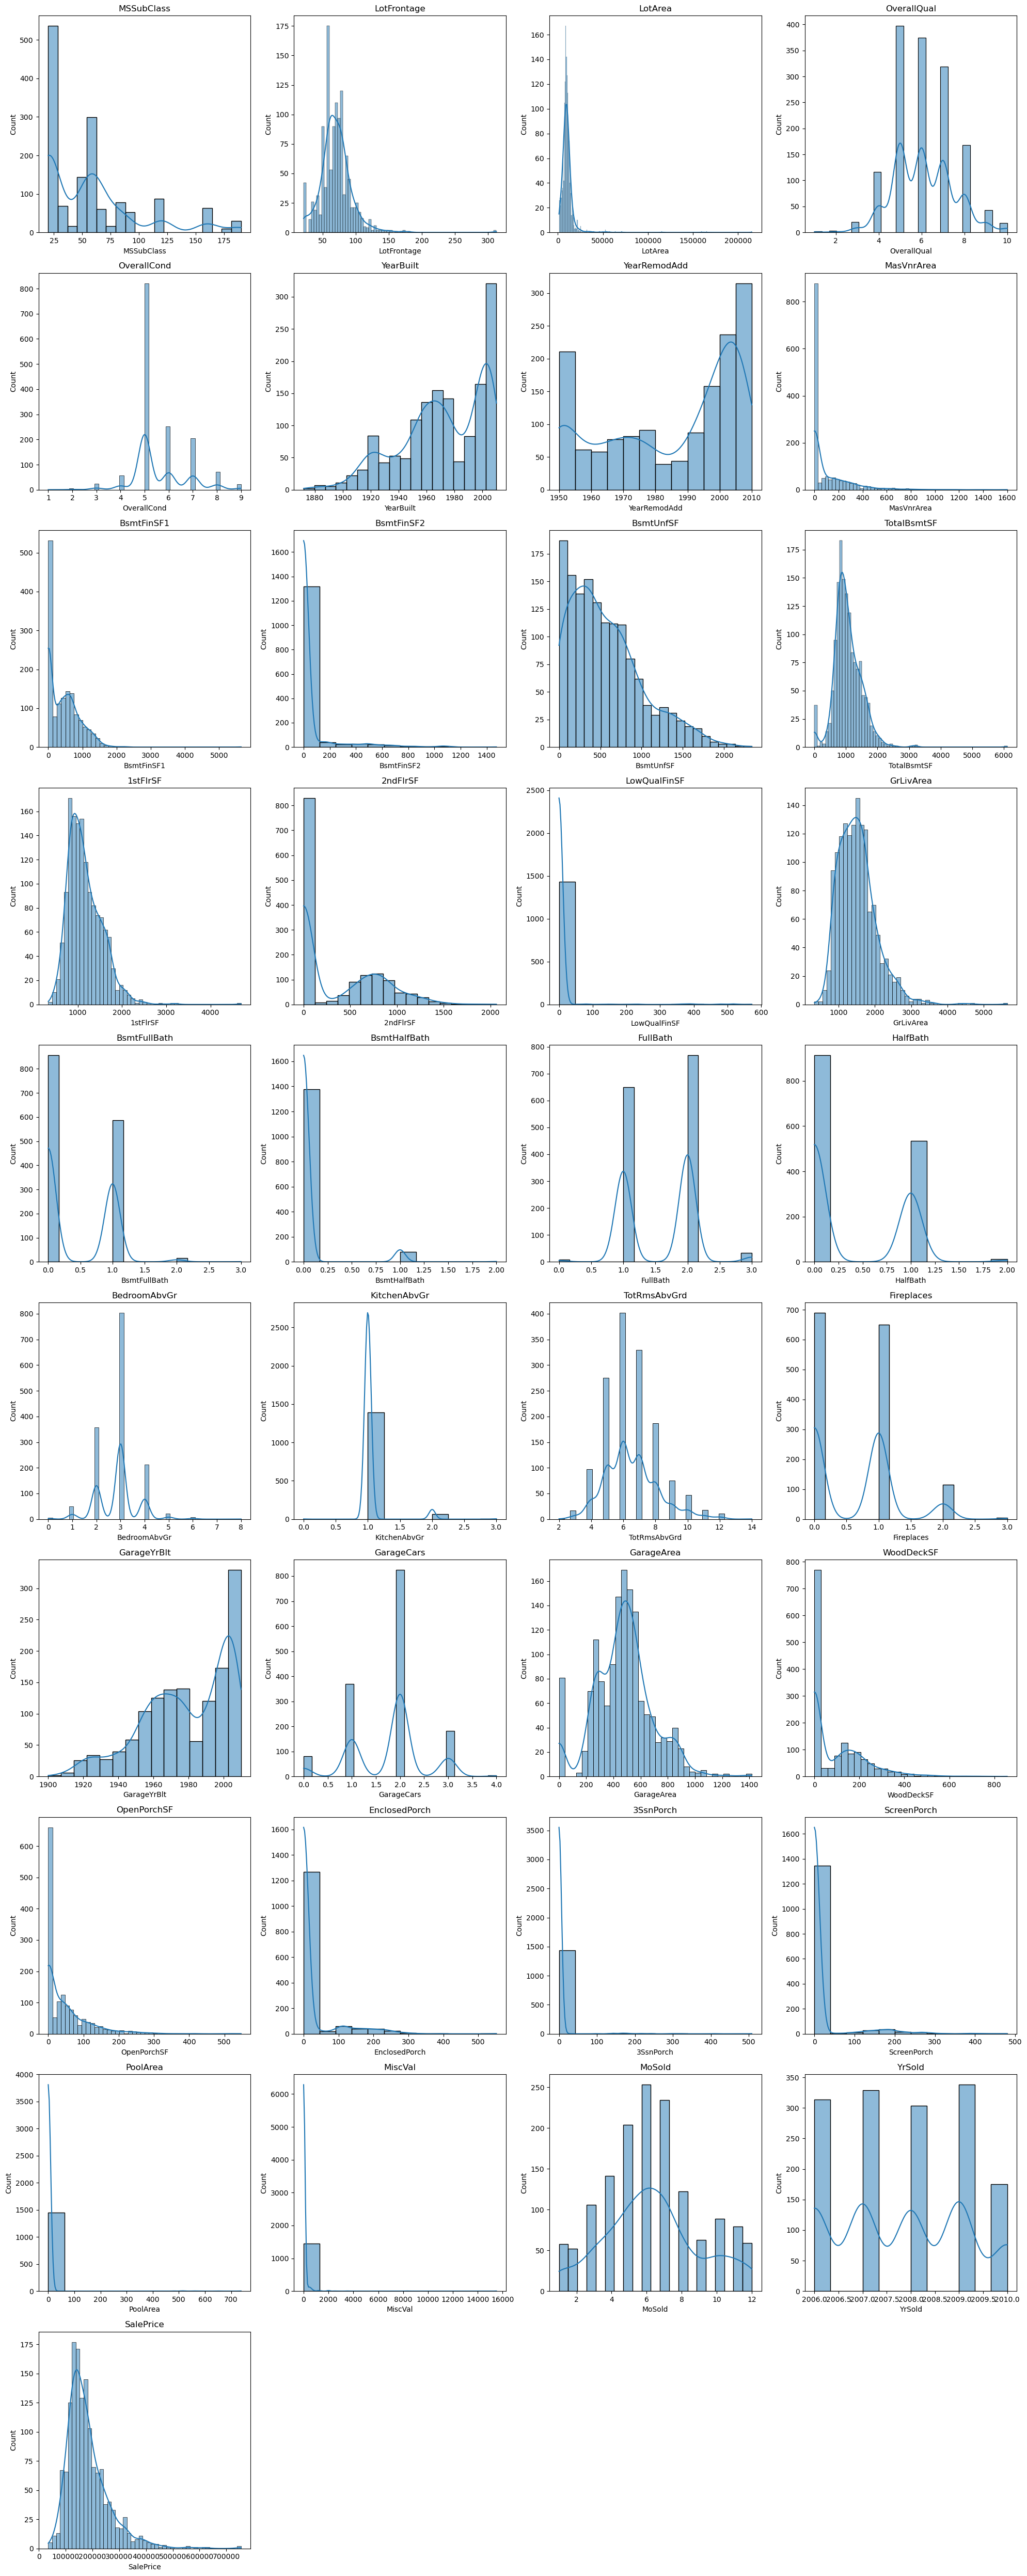

In [21]:
import math

cols = 4
rows = math.ceil(len(num_cols) / cols)

plt.figure(figsize=(20, 5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.histplot(data[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

#### Insights:
* Many numerical features are positively skewed, indicating non-normal distribution.

* A few features show approximately normal distribution, suggesting stable data.

* Presence of extreme values suggests potential outliers in the dataset.

* Skewed features may require transformation (e.g., log transformation).

* Outliers may need to be handled to prevent bias in modeling.

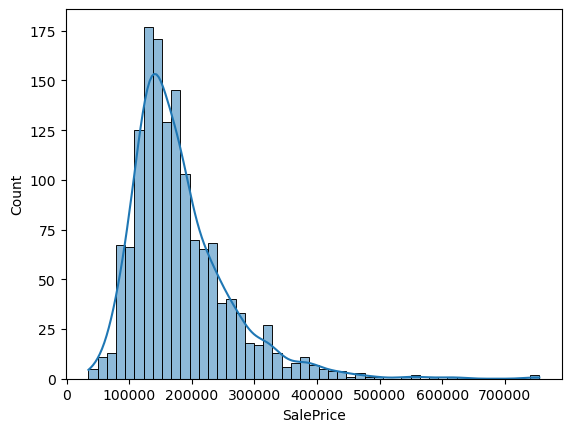

In [22]:
sns.histplot(data['SalePrice'], kde=True)
plt.show()

In [23]:
data['SalePrice'] = np.log1p(data['SalePrice'])

<Axes: xlabel='SalePrice', ylabel='Count'>

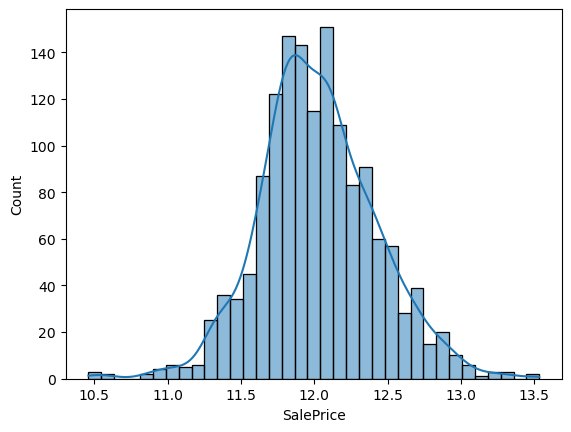

In [24]:
sns.histplot(data['SalePrice'], kde=True)

#### Insights: 
The SalePrice variable showed a right-skewed distribution, indicating the presence of high-value outliers. After applying log transformation, the distribution became more symmetric and closer to normal. This confirms that the transformation was effective in reducing skewness and improving the data distribution for further analysis.

In [25]:
skewness = data[num_cols].skew().sort_values(ascending=False)
skewness

MiscVal          24.476794
PoolArea         14.828374
LotArea          12.207688
3SsnPorch        10.304342
LowQualFinSF      9.011341
KitchenAbvGr      4.488397
BsmtFinSF2        4.255261
ScreenPorch       4.122214
BsmtHalfBath      4.103403
EnclosedPorch     3.089872
MasVnrArea        2.669084
OpenPorchSF       2.364342
LotFrontage       2.163569
BsmtFinSF1        1.685503
WoodDeckSF        1.541376
TotalBsmtSF       1.524255
MSSubClass        1.407657
1stFlrSF          1.376757
GrLivArea         1.366560
BsmtUnfSF         0.920268
2ndFlrSF          0.813030
OverallCond       0.693067
TotRmsAbvGrd      0.676341
HalfBath          0.675897
Fireplaces        0.649565
BsmtFullBath      0.596067
OverallQual       0.216944
MoSold            0.212053
BedroomAbvGr      0.211790
GarageArea        0.179981
SalePrice         0.121347
YrSold            0.096269
FullBath          0.036562
GarageCars       -0.342549
YearRemodAdd     -0.503562
YearBuilt        -0.613461
GarageYrBlt      -0.649415
d

In [26]:
skewed_cols = skewness[skewness > 1].index
skewed_cols

Index(['MiscVal', 'PoolArea', 'LotArea', '3SsnPorch', 'LowQualFinSF',
       'KitchenAbvGr', 'BsmtFinSF2', 'ScreenPorch', 'BsmtHalfBath',
       'EnclosedPorch', 'MasVnrArea', 'OpenPorchSF', 'LotFrontage',
       'BsmtFinSF1', 'WoodDeckSF', 'TotalBsmtSF', 'MSSubClass', '1stFlrSF',
       'GrLivArea'],
      dtype='object')

In [27]:
for col in skewed_cols:
    data[col] = np.log1p(data[col])

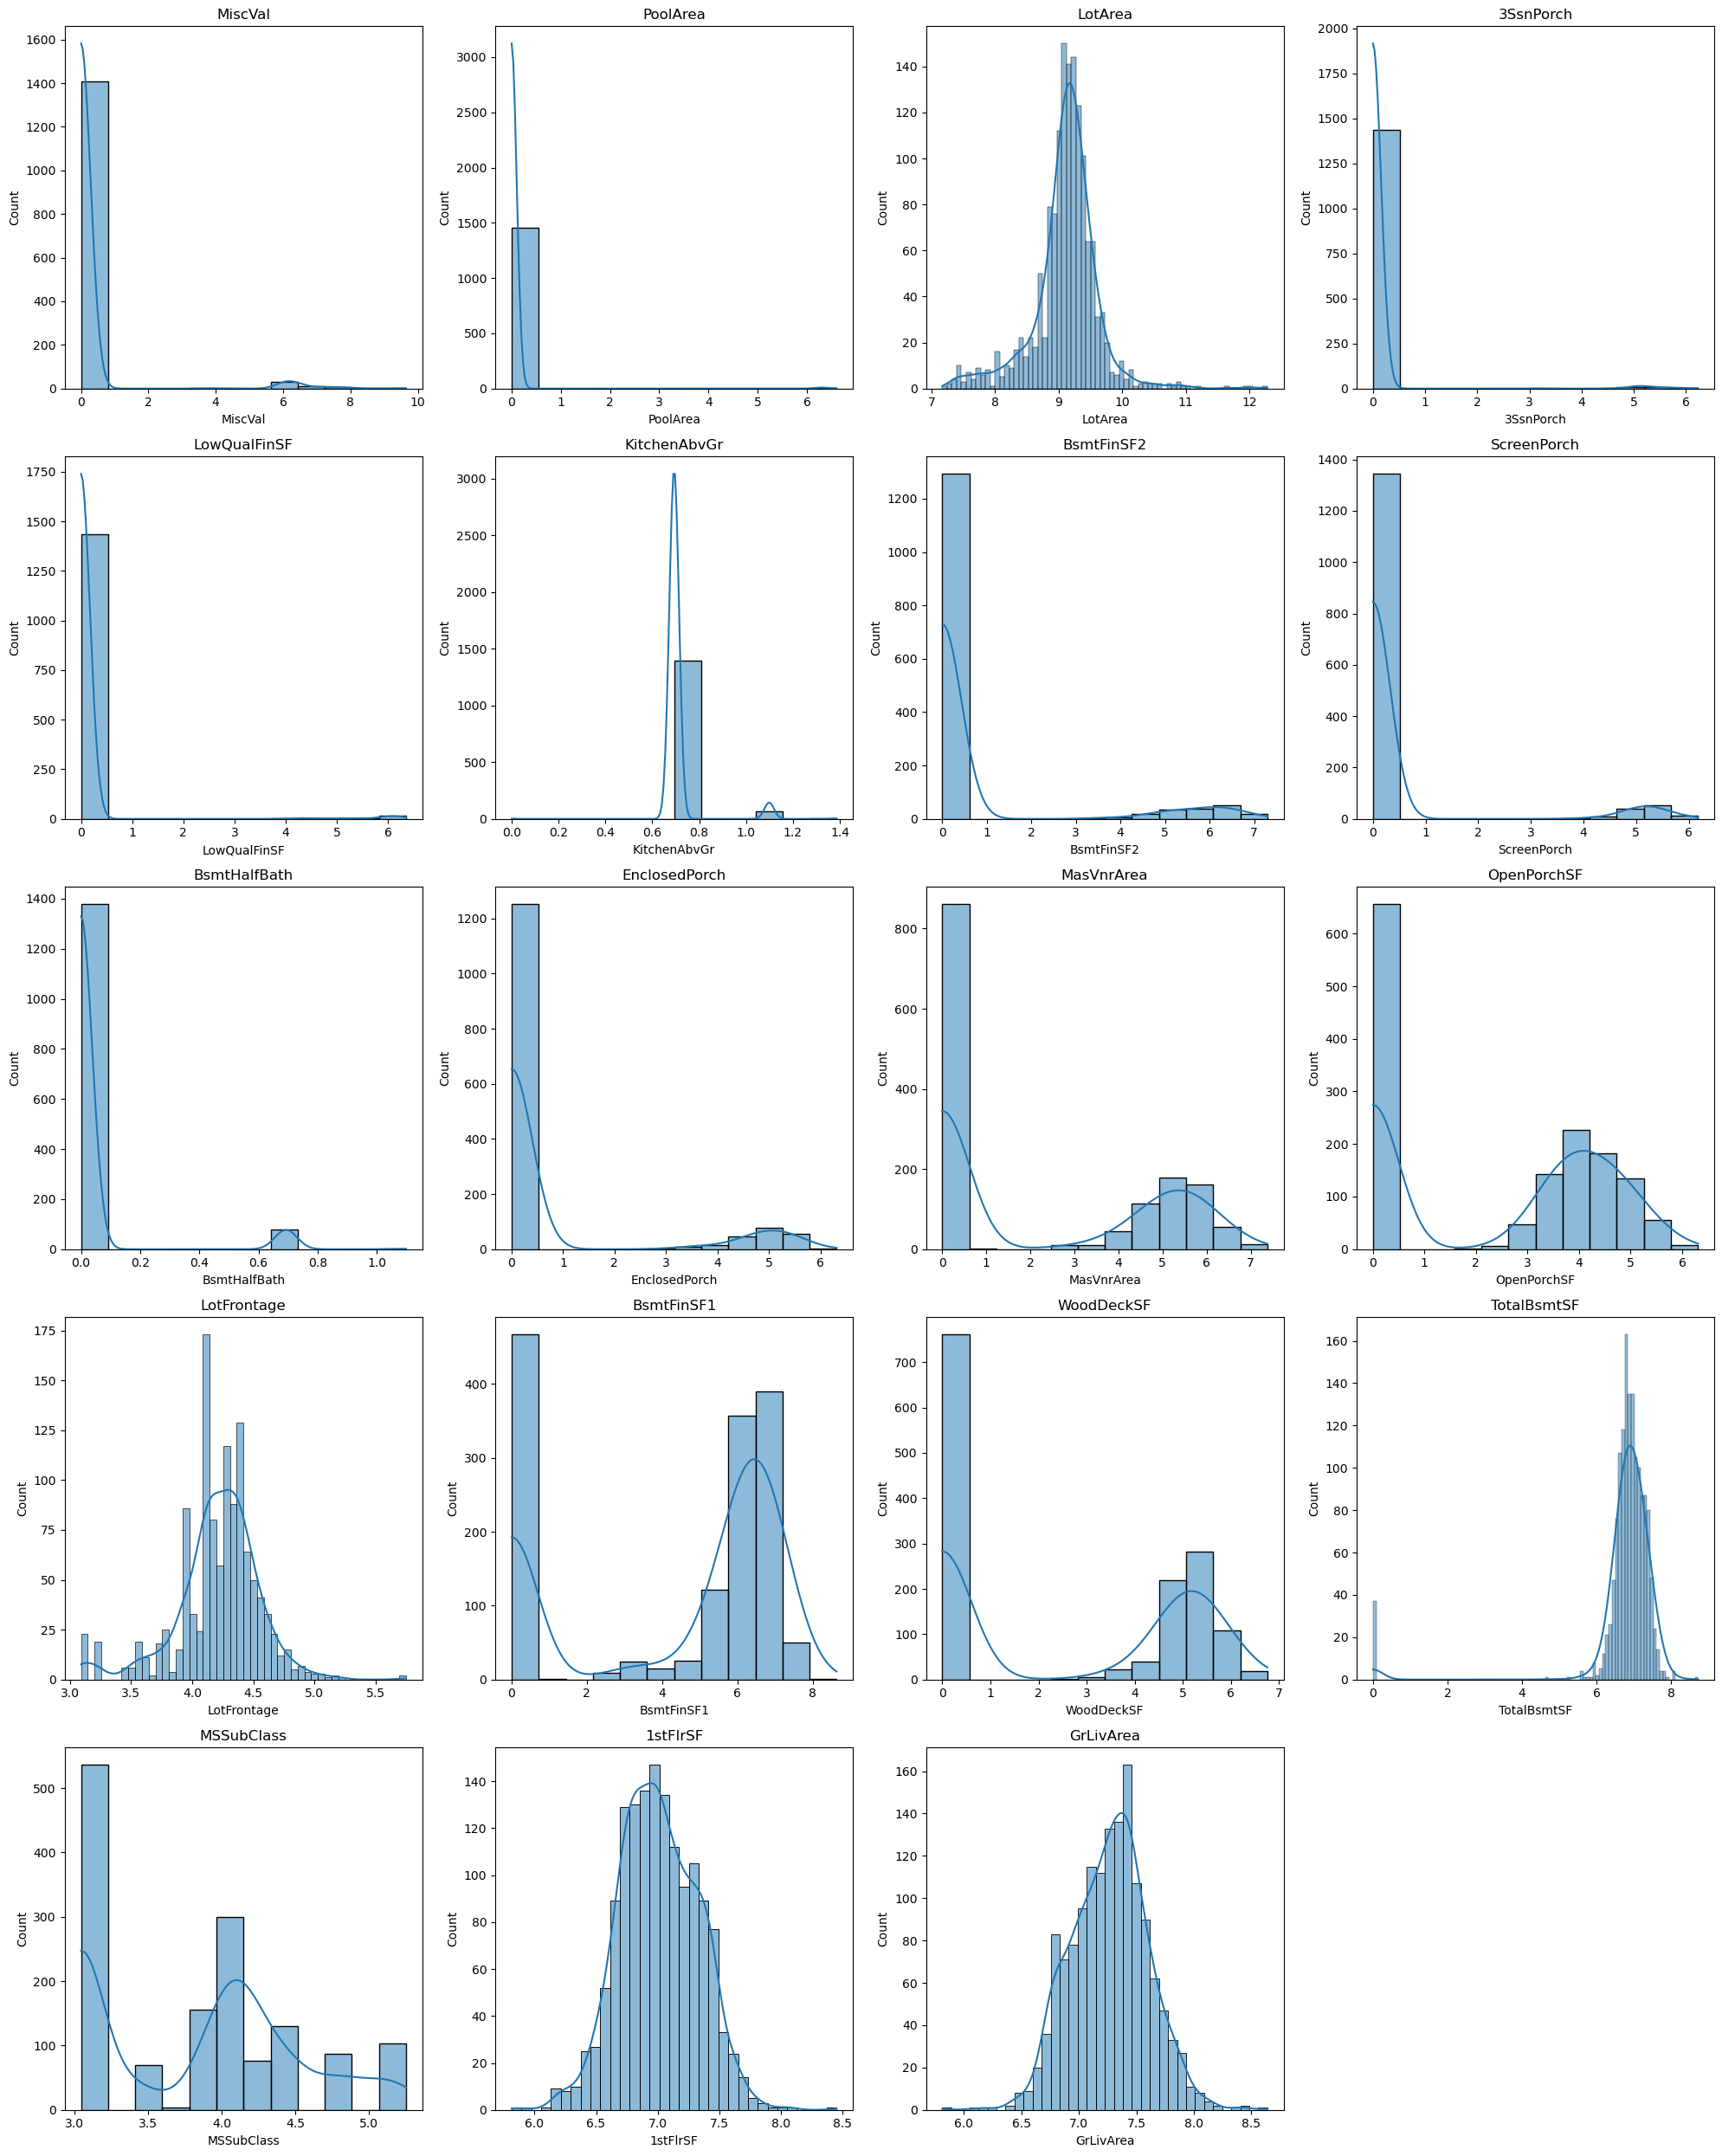

In [28]:
cols = 4  
rows = math.ceil(len(skewed_cols) / cols)

plt.figure(figsize=(20,5 * rows))

for i, col in enumerate(skewed_cols, 1):
    plt.subplot(rows, cols, i)
    sns.histplot(data[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

#### Insights:
Log transformation was applied to highly skewed numerical features to normalize their distribution. This helps in reducing the impact of extreme values and improves the performance of machine learning models.


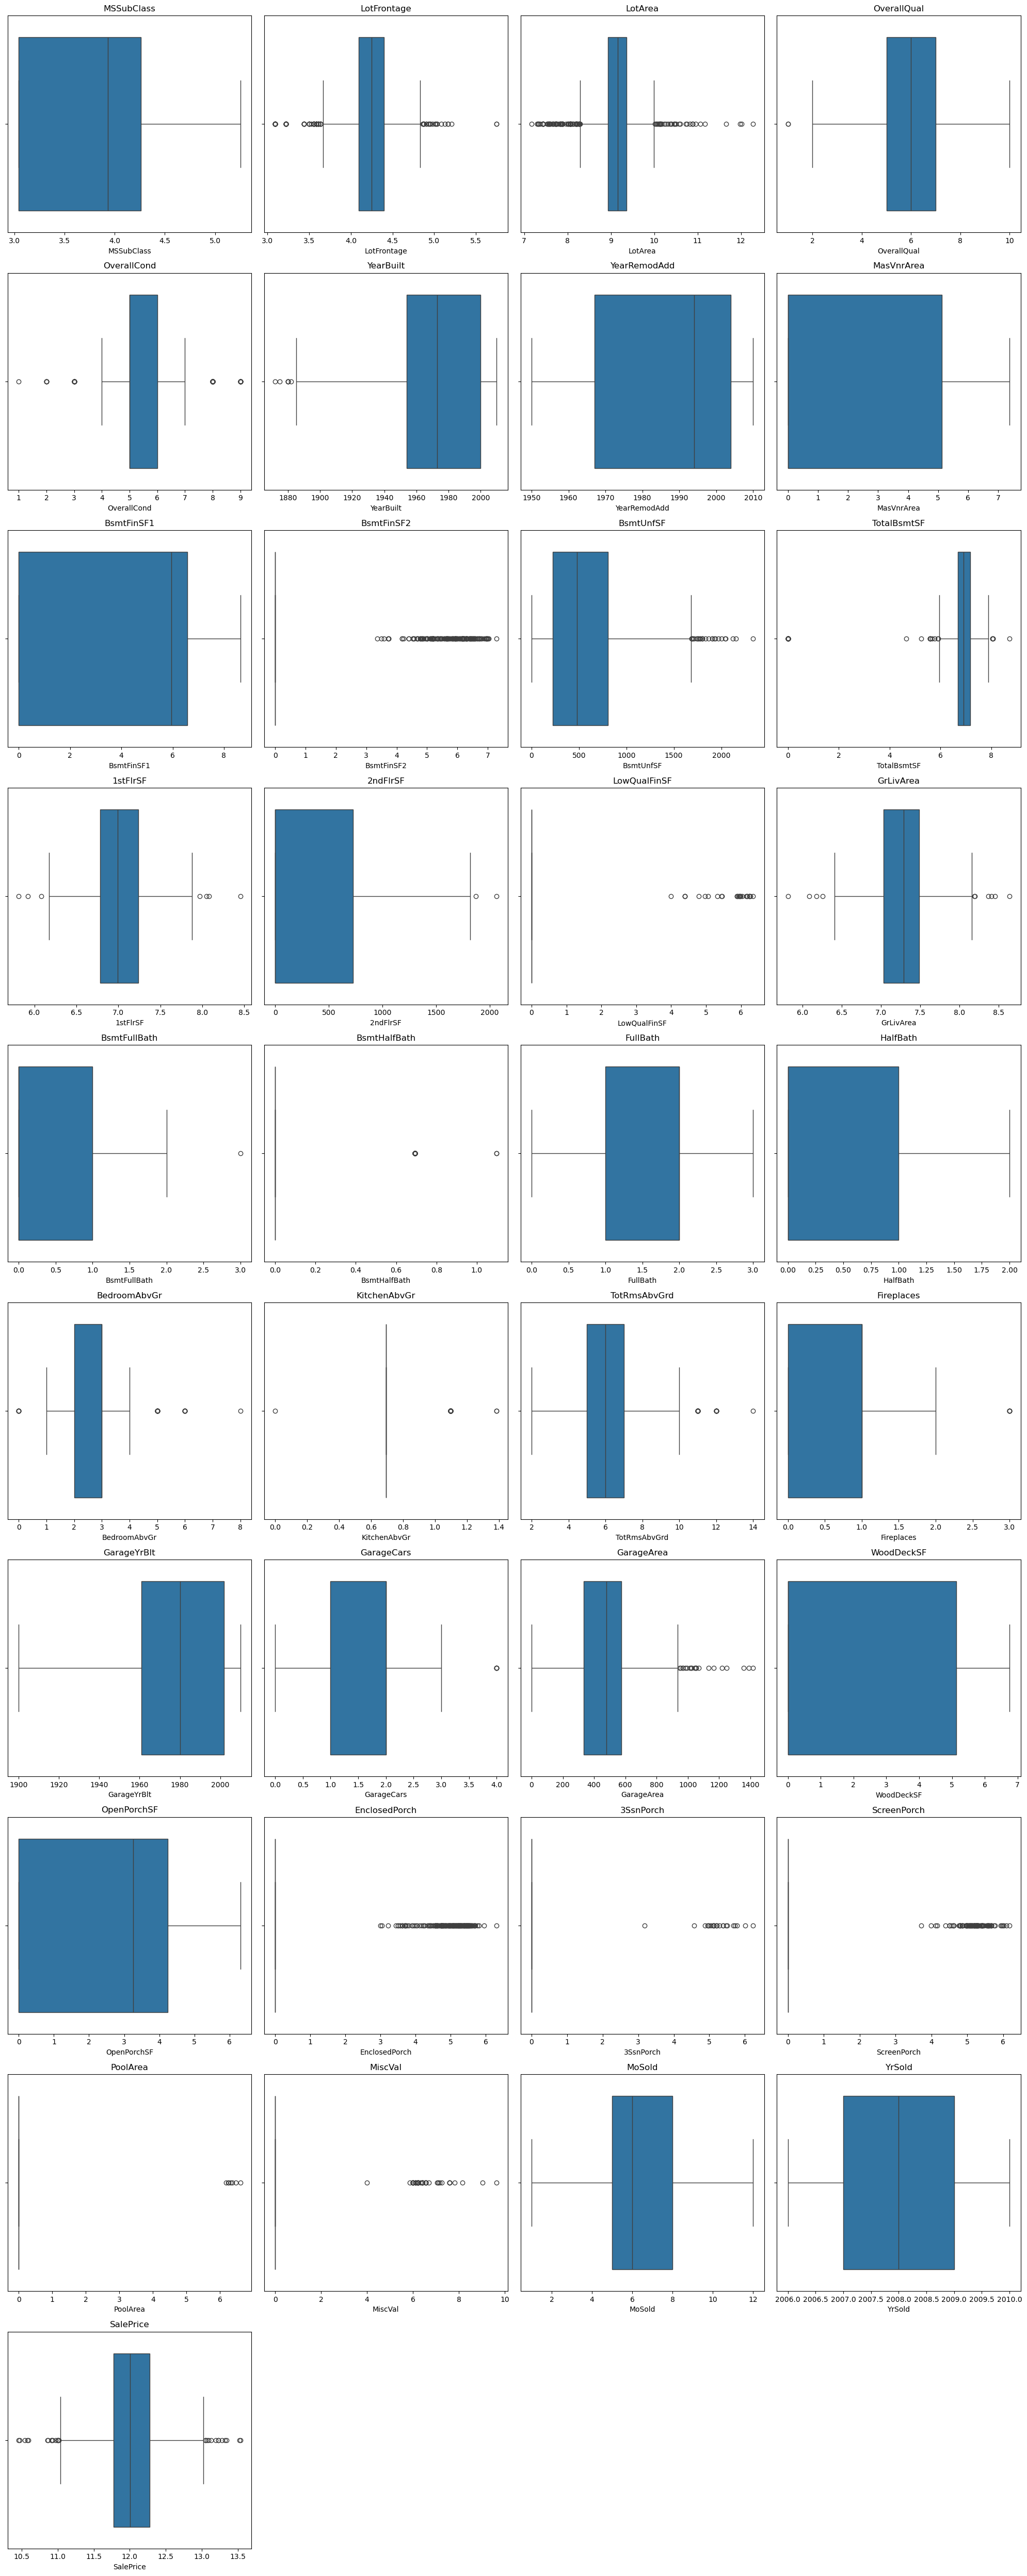

In [29]:
cols = 4
rows = math.ceil(len(num_cols) / cols)

plt.figure(figsize=(20, 5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

#### Insights:

Boxplots were used to visualize the distribution of numerical features and detect outliers. Several features exhibit points beyond the whiskers, indicating the presence of outliers. The spread of data varies across features, with some showing high variability and others being more concentrated.

These observations suggest that certain features may require outlier treatment or transformation to improve data quality and ensure better model performance.


### 7. Bivariate Analysis For Numerical Features:
  * Shows relationship between feature and SalePrice.
  * shows correlation between multiple variables.

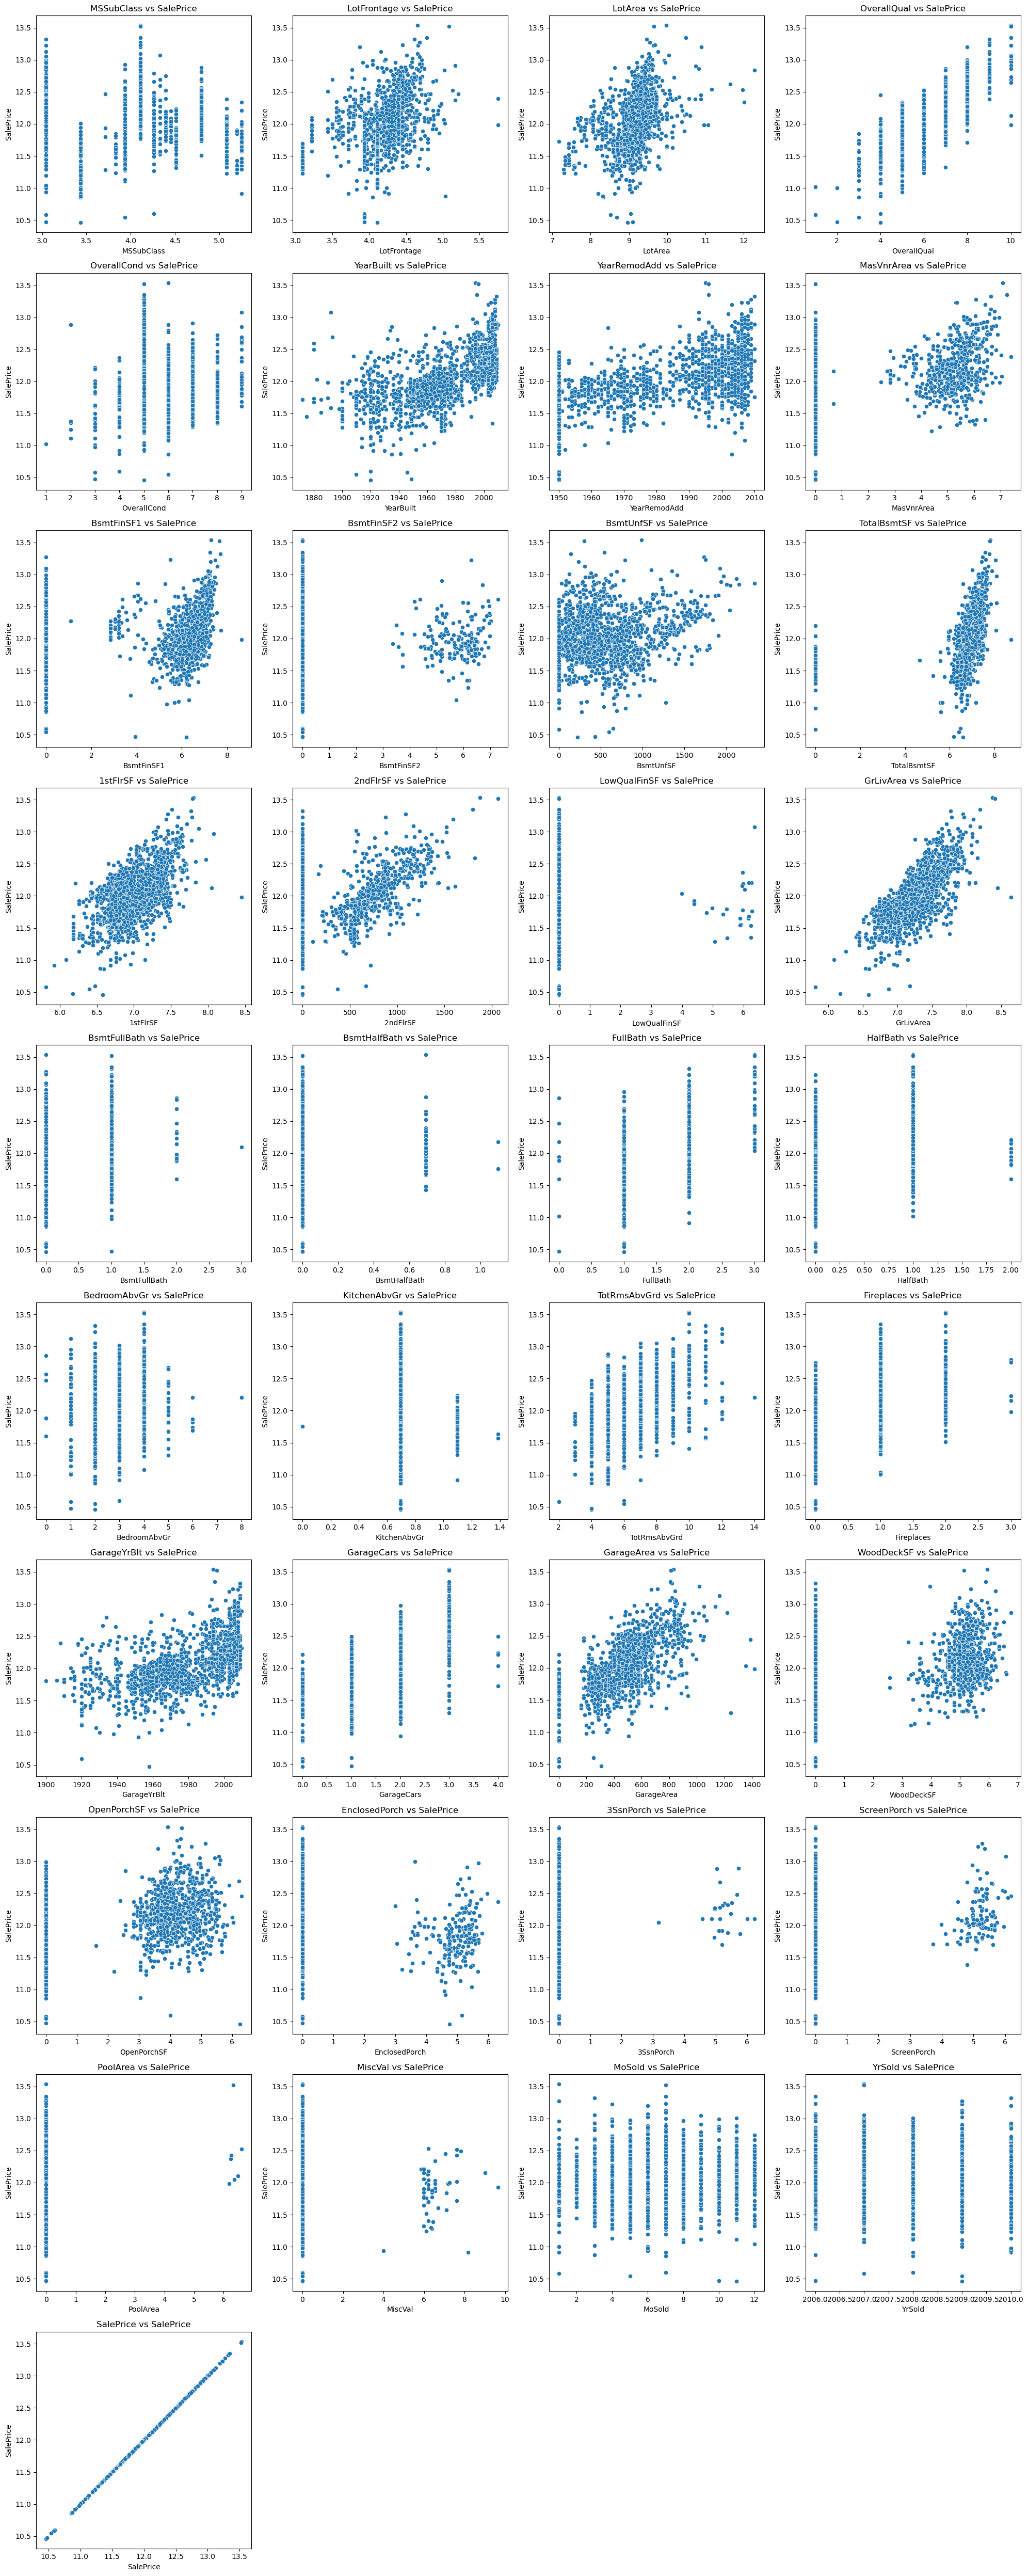

In [30]:
cols = 4
rows = math.ceil(len(num_cols) / cols)

plt.figure(figsize=(20,5 * rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(rows, cols, i)
    sns.scatterplot(x=data[col], y=data['SalePrice'])
    plt.title(f"{col} vs SalePrice")

plt.tight_layout()
plt.show()

#### Insights:

* Scatter plots were used to analyze the relationship between numerical features and the target variable (SalePrice).

* Features such as GrLivArea and OverallQual show a strong positive relationship with SalePrice, indicating that higher values of these features lead     to higher house prices.

* Several features exhibit weak or no clear relationship, suggesting they have limited impact on the target variable.

* The presence of scattered points and extreme values indicates potential outliers in the dataset.

* These outliers may negatively affect model performance if not handled properly.

* Overall, this analysis helps in identifying important numerical features and understanding their influence on house prices.


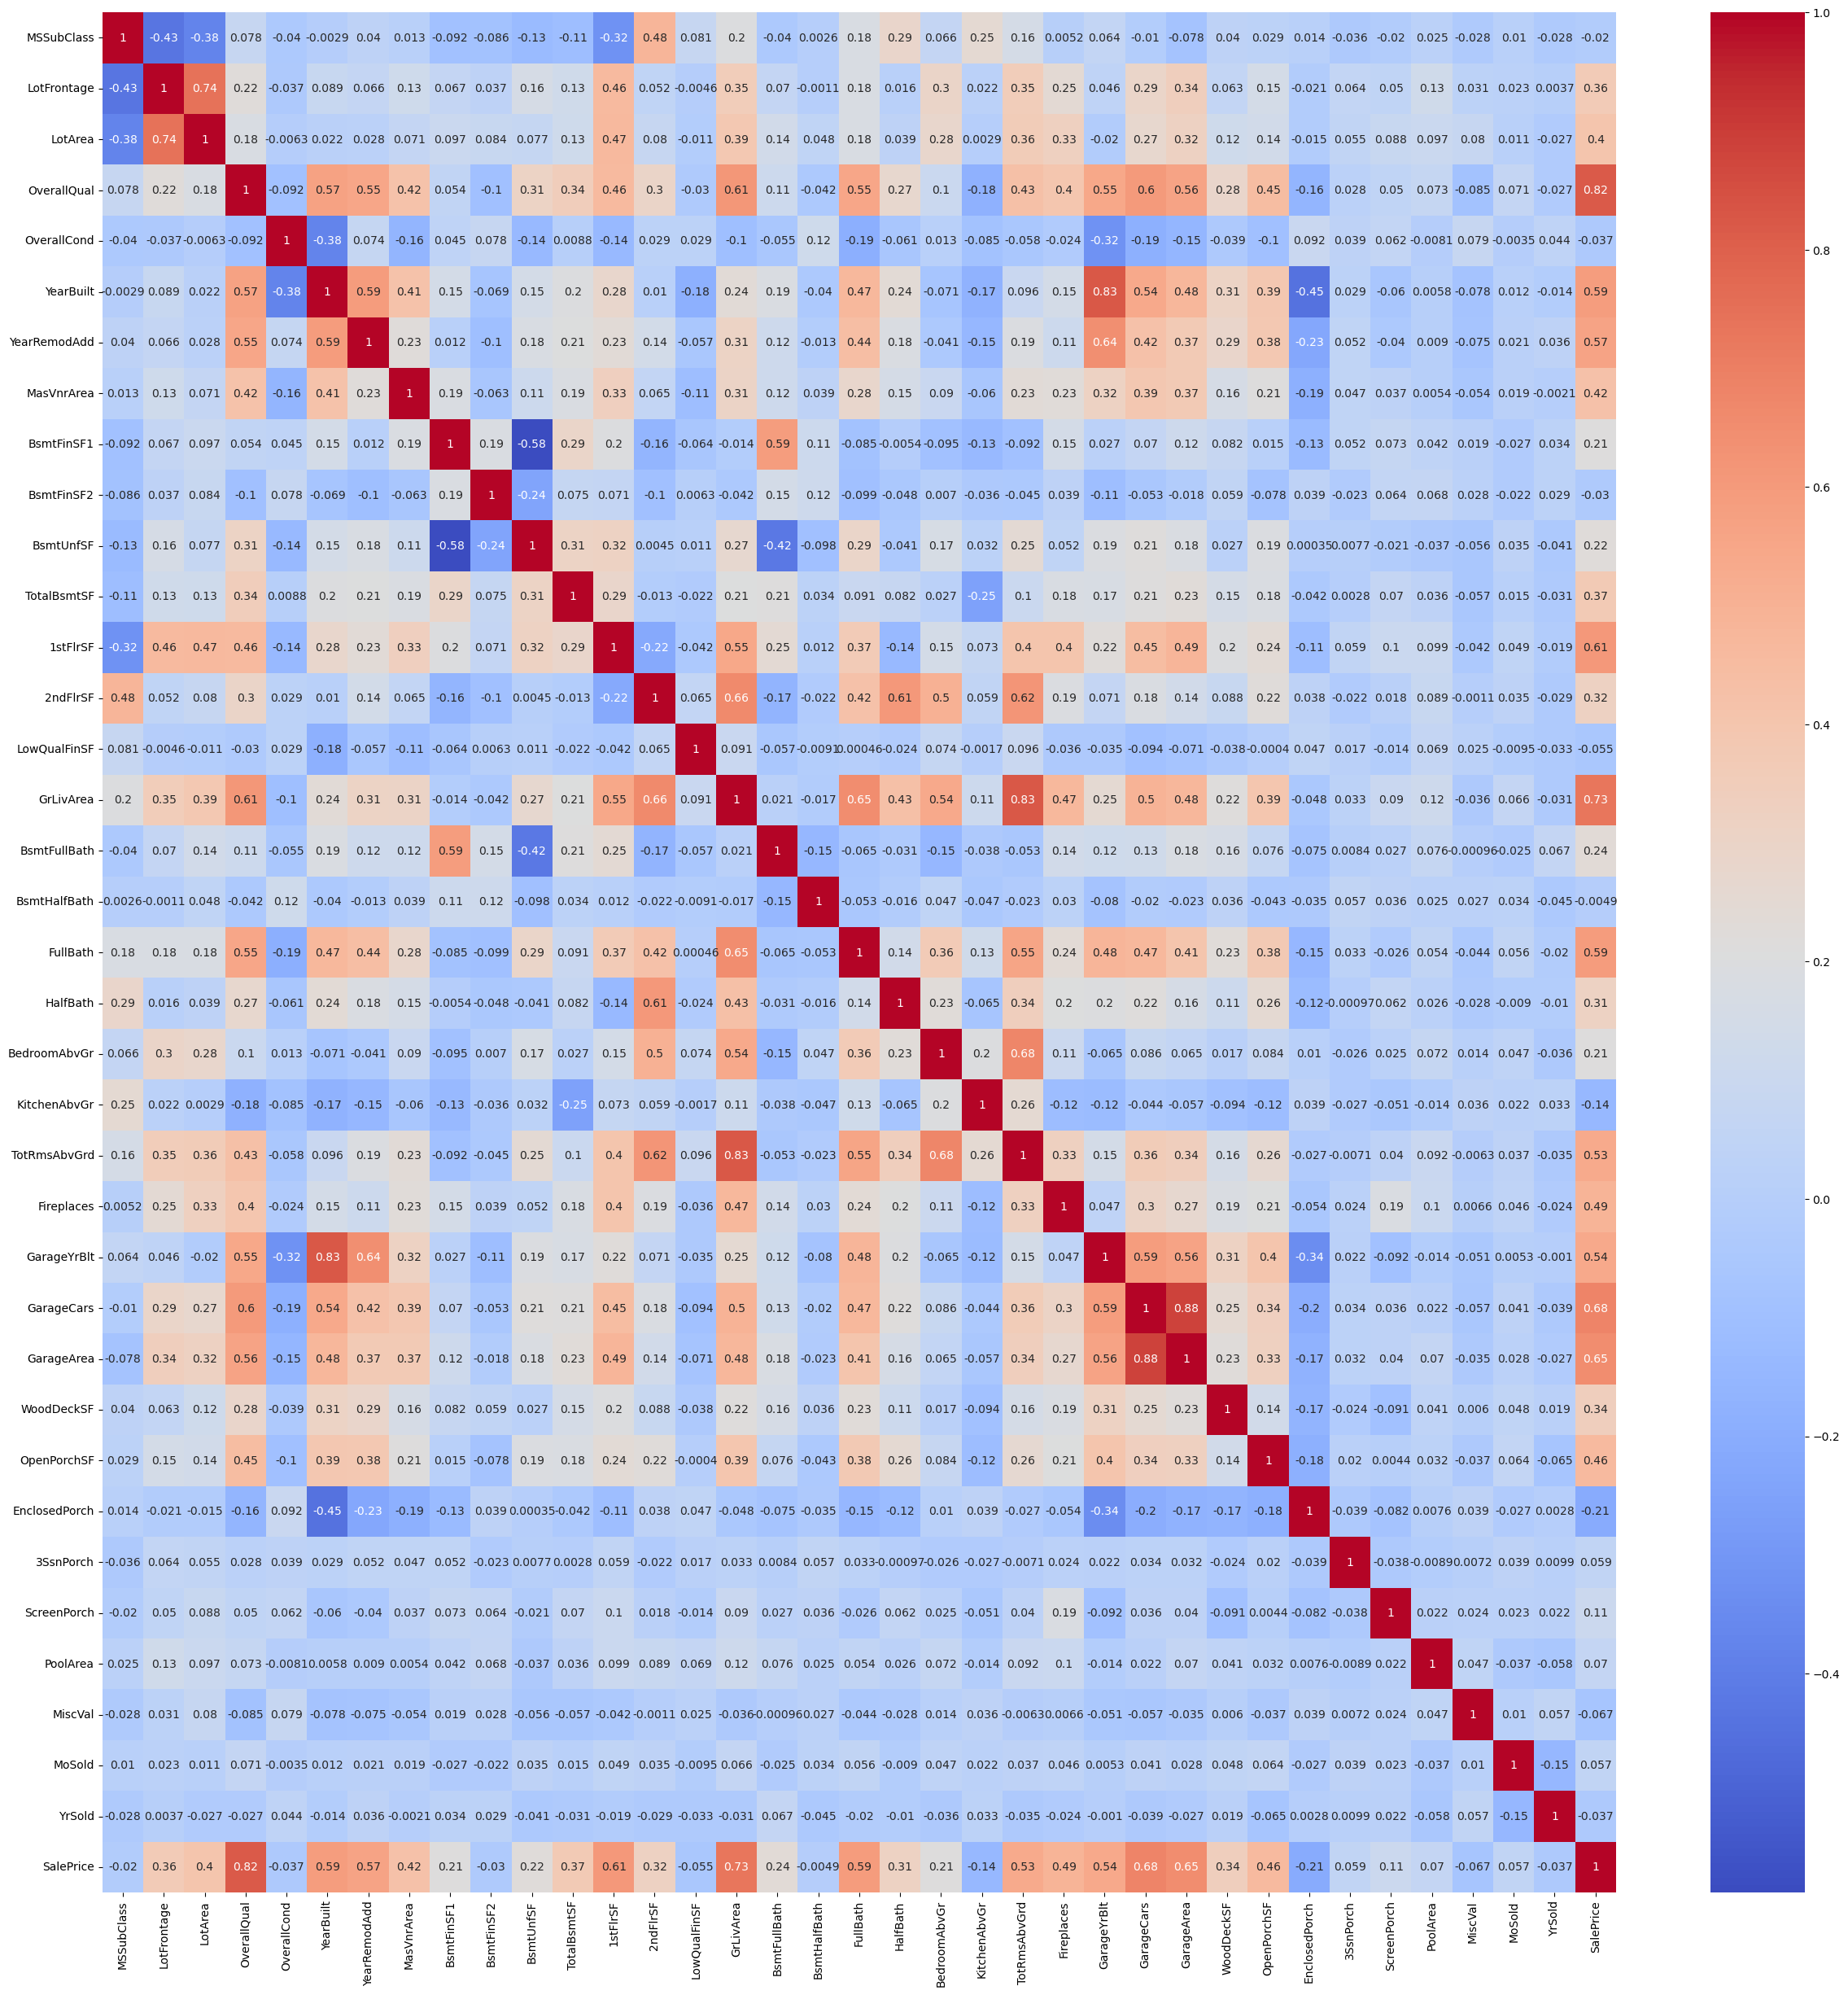

In [31]:
corr = data[num_cols].corr()

plt.figure(figsize=(30,30))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

#### Insights:

* A correlation heatmap was used to examine the relationships among numerical features in the dataset.

* It was observed that features such as "GrLivArea" and "OverallQual", show a strong positive correlation with the target variable (SalePrice),   indicating their significant influence on house prices.

* Some features exhibit weak or negligible correlation with SalePrice, suggesting they may have limited predictive importance.

* Additionally, certain features are highly correlated with each other, indicating the presence of multicollinearity in the dataset.

* This multicollinearity may affect model performance and should be considered during feature selection or model building.

* Overall, the heatmap helps in identifying important features and understanding relationships within the dataset.


### 8. Multivariate Analysis For Numerical Features:
  * Shows how multiple numerical features together affect SalePrice.

In [32]:
corr = data[num_cols].corr()['SalePrice'].abs().sort_values(ascending=False)

top_features = corr.head(5).index
top_features

Index(['SalePrice', 'OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea'], dtype='object')

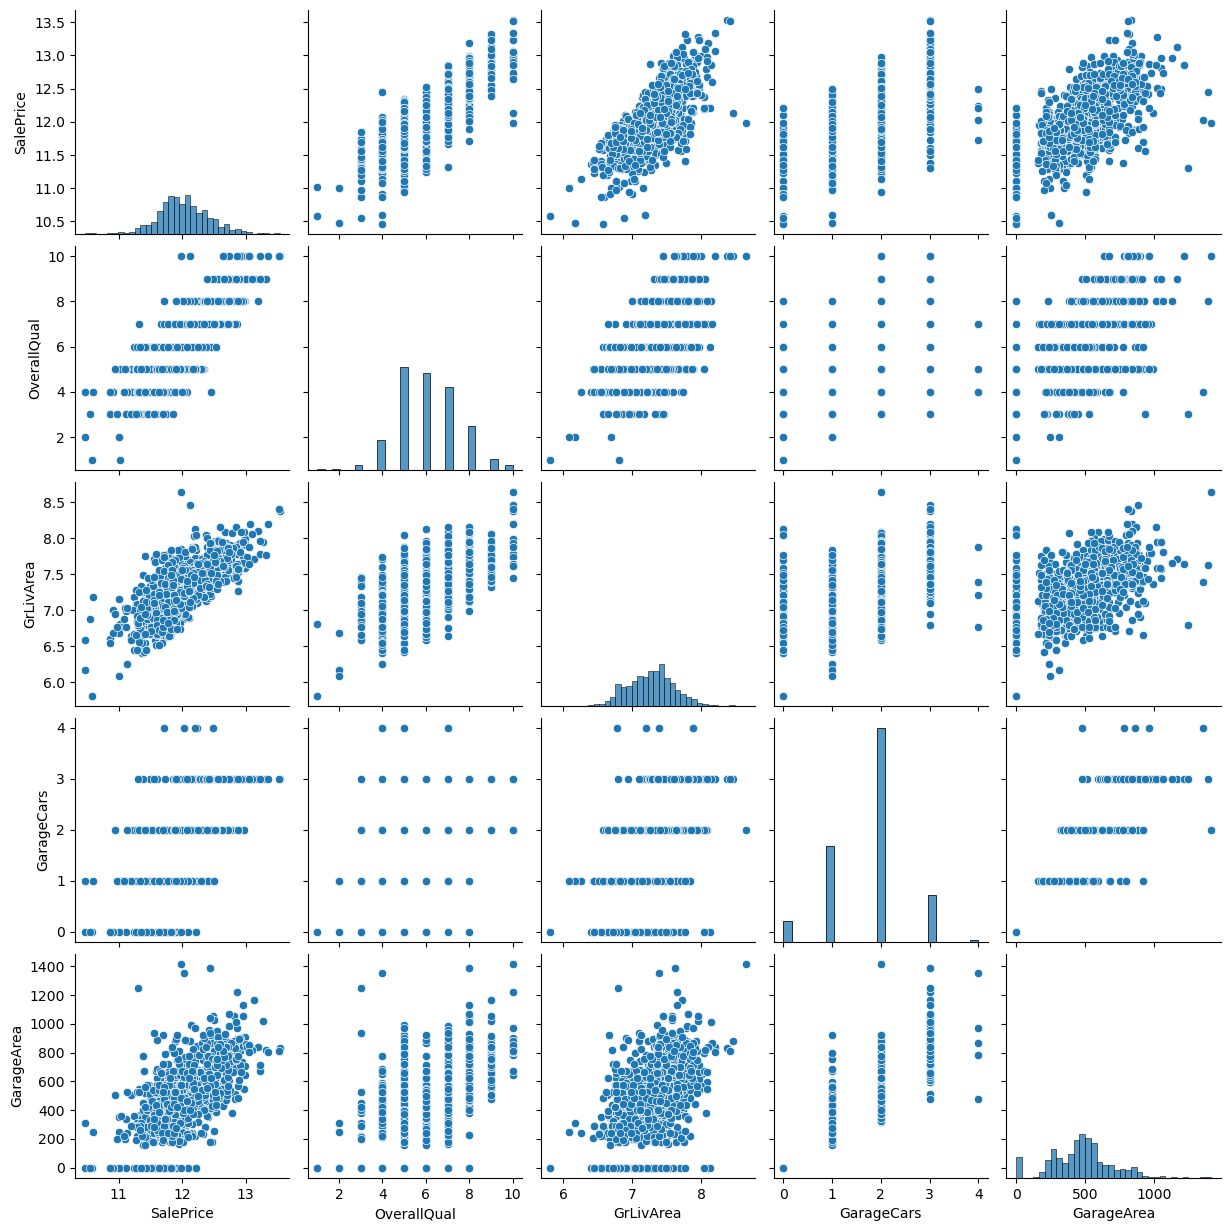

In [33]:
sns.pairplot(data[top_features])
plt.show()

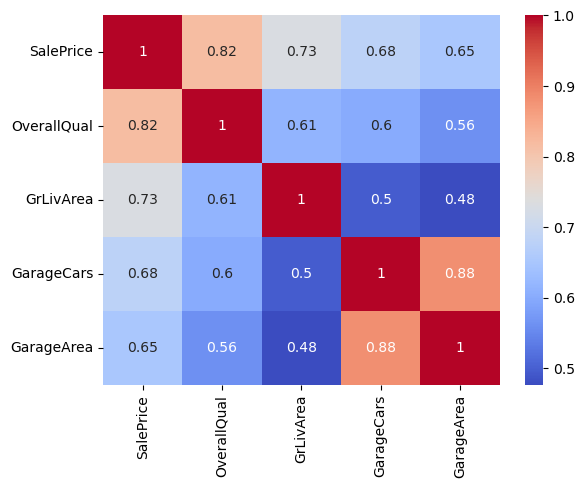

In [34]:
sns.heatmap(data[top_features].corr(), annot=True, cmap='coolwarm')
plt.show()

#### Insights:

* Multivariate analysis was performed using pairplots and correlation heatmaps to understand the relationships among multiple numerical features.

* The pairplot shows that certain features exhibit clear patterns and relationships with the target variable (SalePrice), indicating their combined influence on house prices.

* The correlation heatmap highlights that some numerical features have strong positive relationships with SalePrice, making them important predictors.

* Overall, this analysis helps in understanding how multiple features interact and contributes to better feature selection for model building.


### 9. Univariate Analysis For Categorical Features:
  * Analysing one categorical variable at a time.

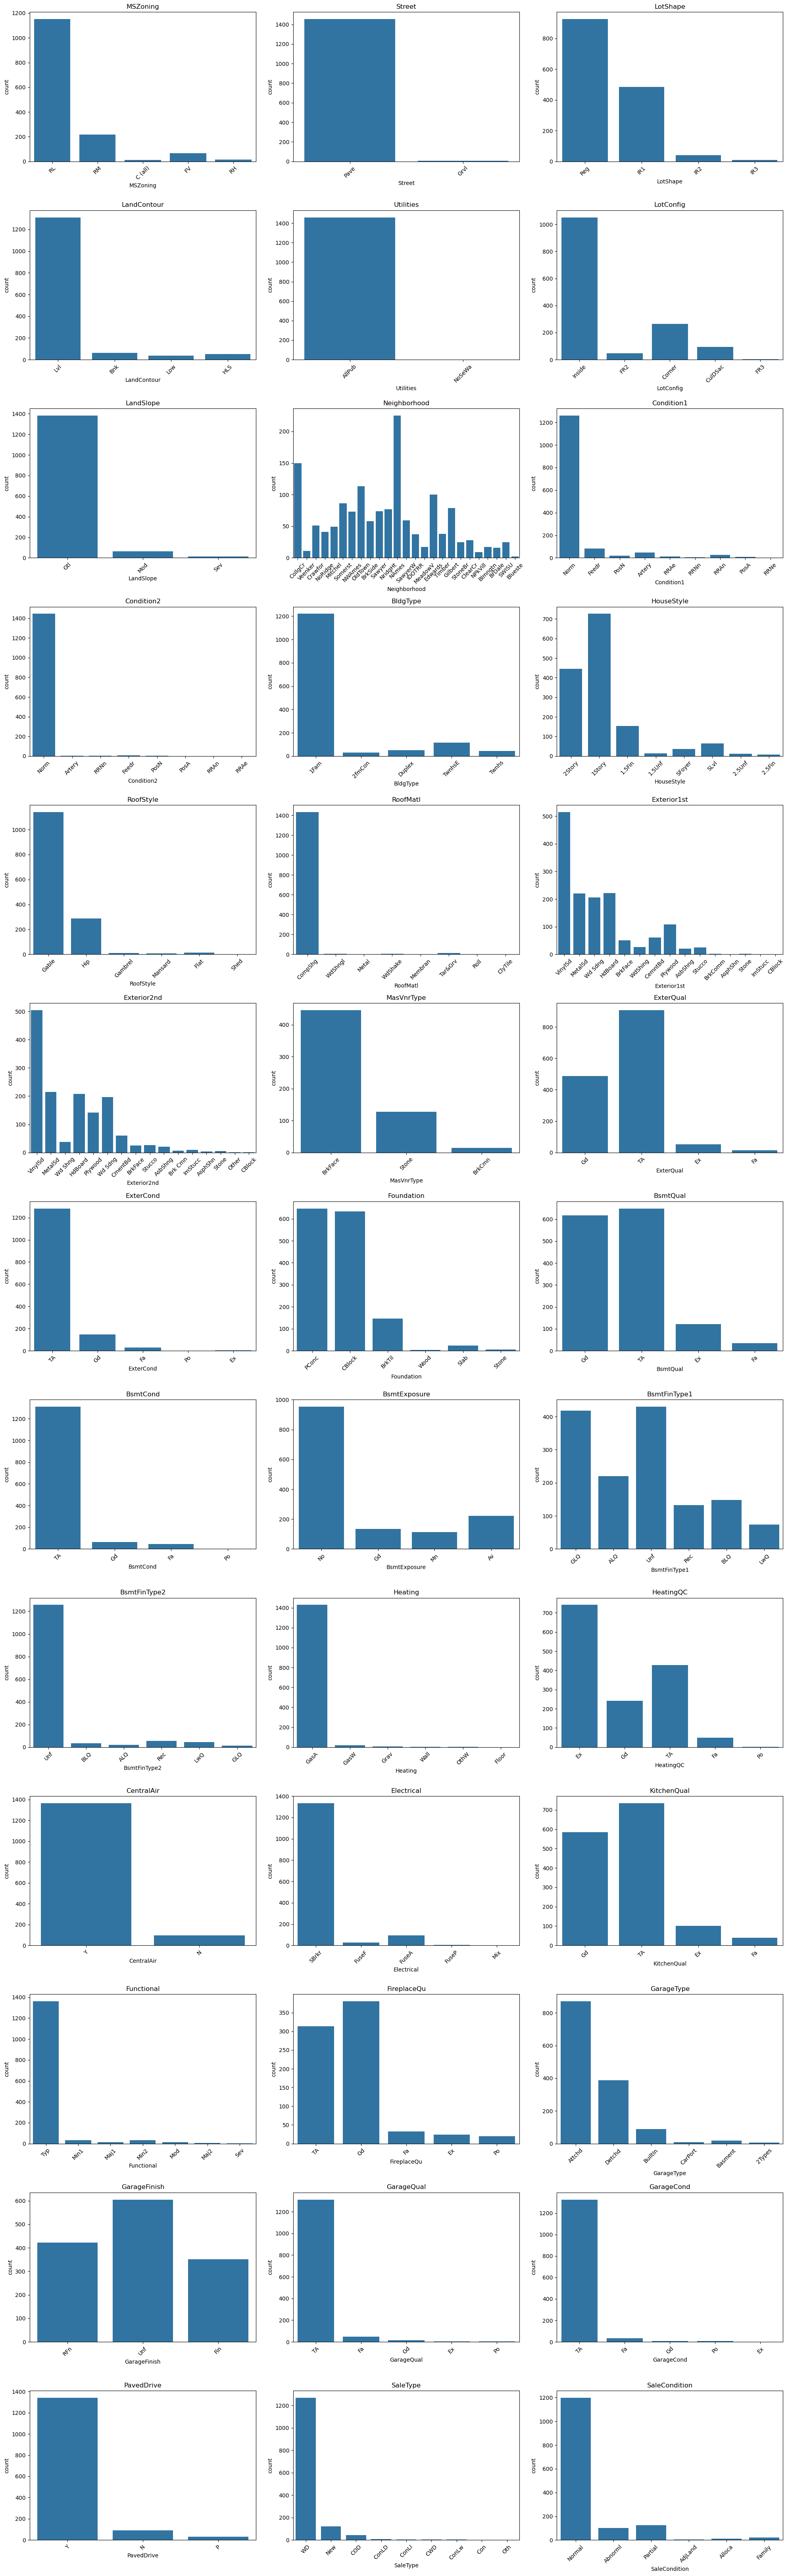

In [35]:
cols = 3
rows = math.ceil(len(cat_cols) / cols)

plt.figure(figsize=(20,5 * rows))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(rows, cols, i)
    sns.countplot(x=data[col])
    plt.title(col)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Insights:

* Categorical features were analyzed using countplots to understand their distribution.

* It was observed that some categories appear more frequently than others, indicating that the data is not evenly distributed.

* A few categories have very low frequency, which may represent rare cases in the dataset.

* Features with too many unique categories may increase complexity during modeling.

* Overall, the analysis helps in understanding the structure of categorical variables and highlights the need for proper handling of rare and dominant categories.


### 10. Bivariate Analysis For Categorical Features:
  * Shows Relationship between categorical feature and SalePrice.

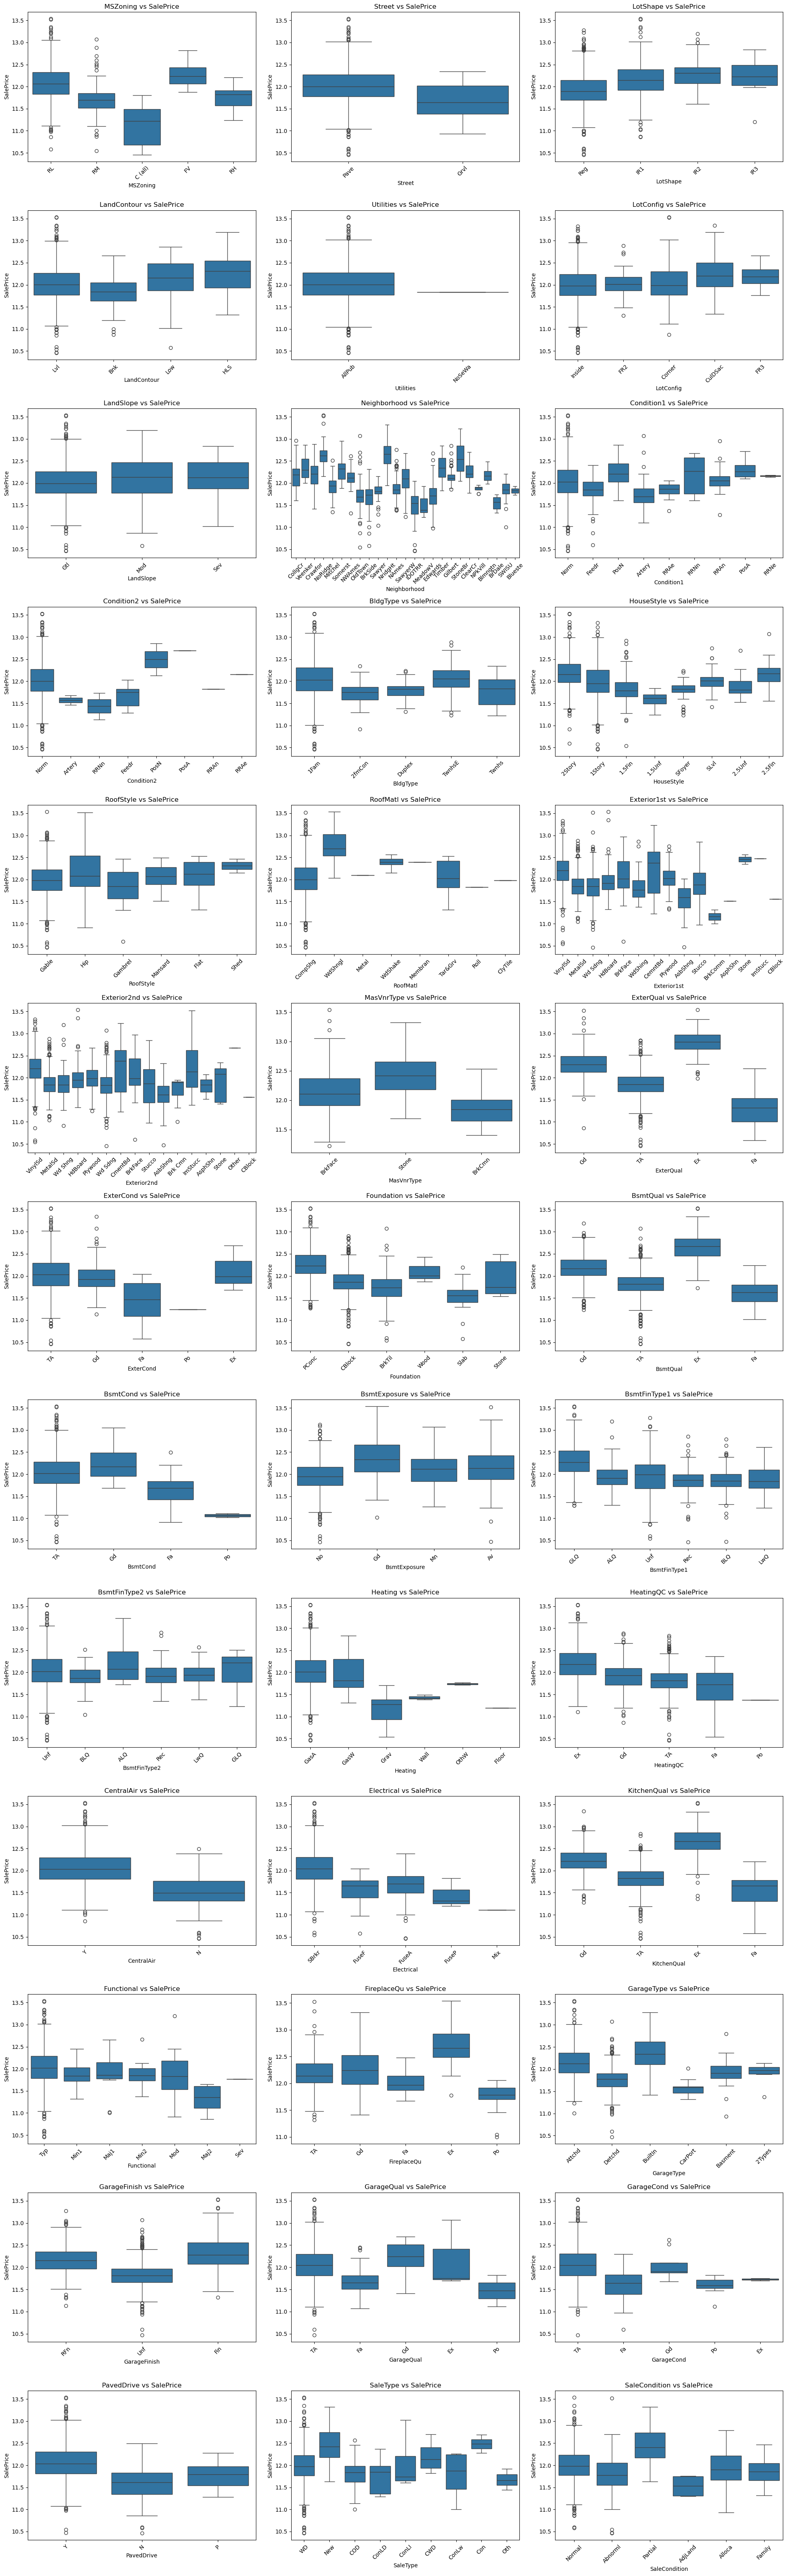

In [36]:
cols = 3
rows = math.ceil(len(cat_cols) / cols)

plt.figure(figsize=(20,5 * rows))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x=data[col], y=data['SalePrice'])
    plt.title(f"{col} vs SalePrice")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Insights:
* Boxplots were used to analyze the relationship between categorical features and SalePrice.

* It was observed that some categories have higher median sale prices, indicating their stronger influence on the target variable.

* In some features, the price distribution varies significantly across categories, showing that they are important for prediction.

* Other features show similar price ranges across categories, suggesting a weaker relationship with SalePrice.

* This analysis helps in identifying which categorical features are more useful for predicting house prices.


### 11. Multivariate Analysis For Categorical Features:
  * shows how one categorical feature affects SalePrice.

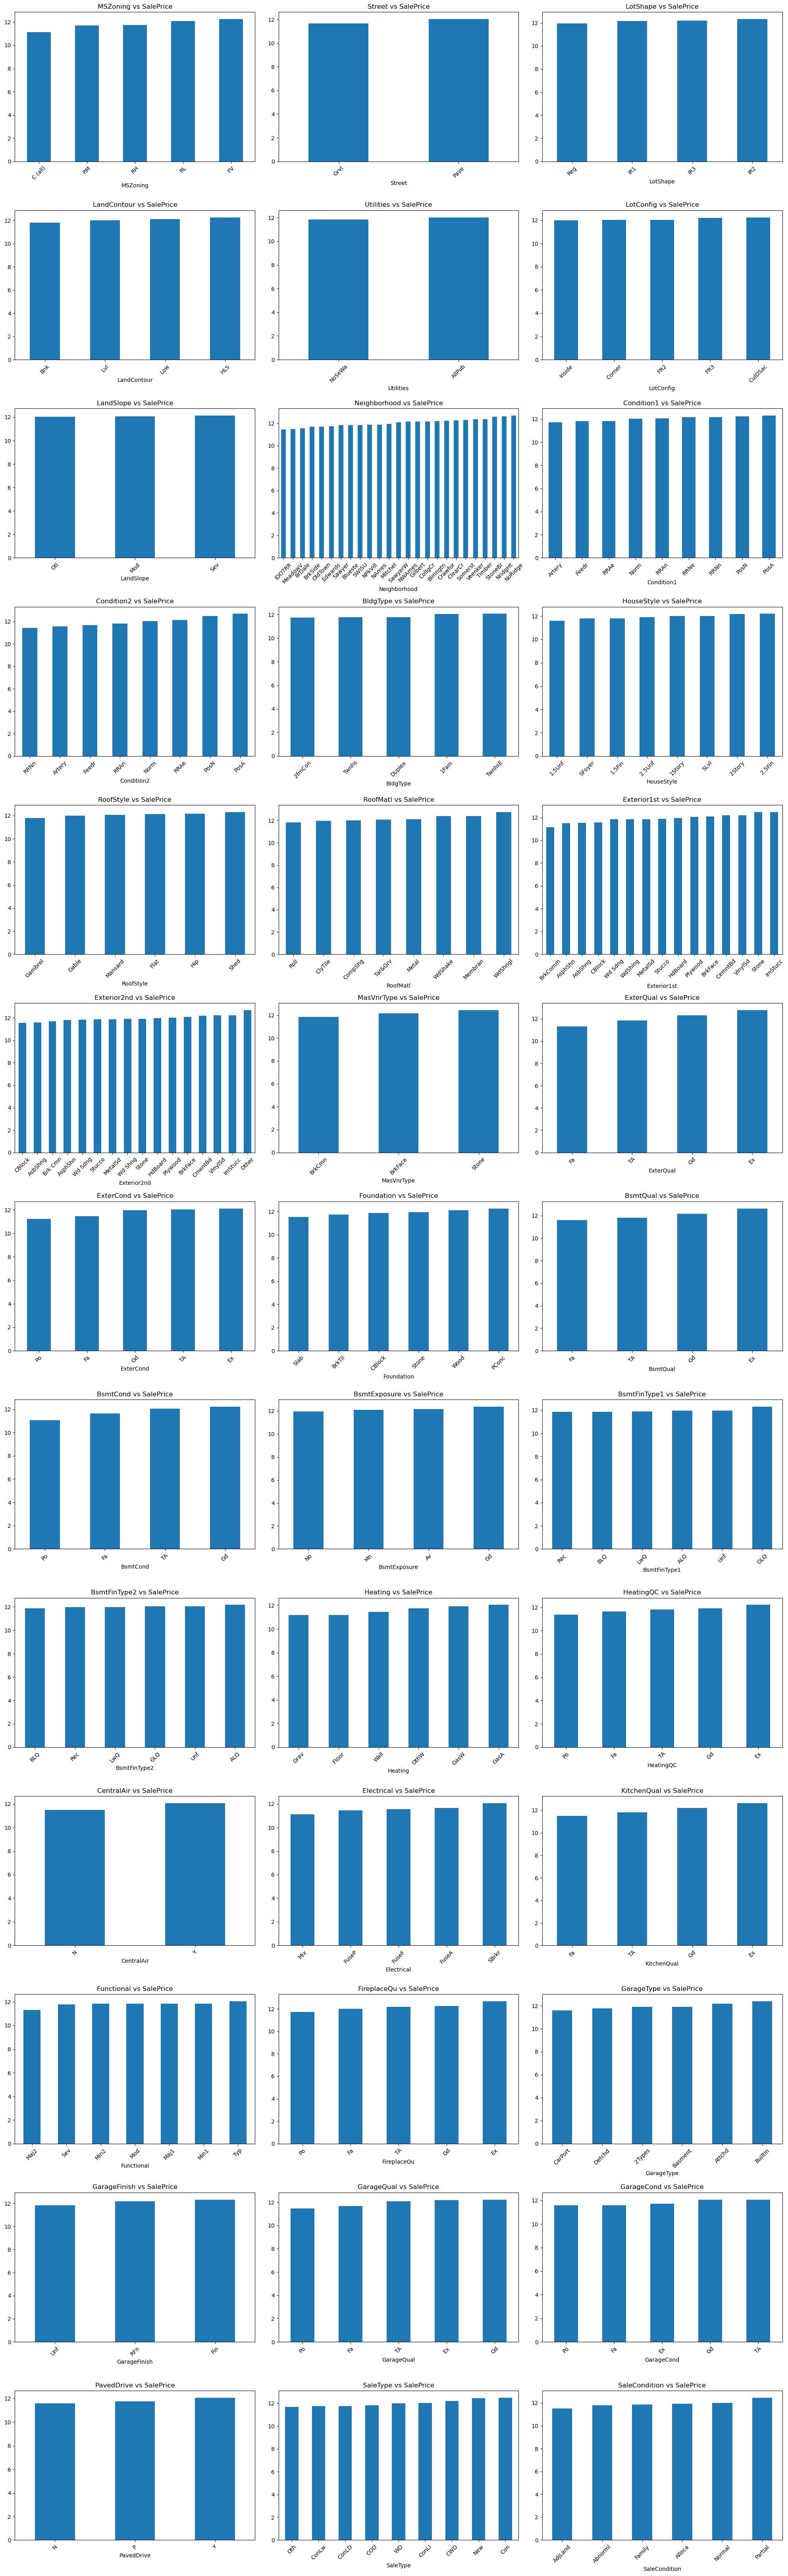

In [37]:
cols = 3
rows = math.ceil(len(cat_cols) / cols)

plt.figure(figsize=(20,5 * rows))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(rows, cols, i)
    
    mean_values = data.groupby(col)['SalePrice'].mean().sort_values()
    mean_values.plot(kind='bar')
    
    plt.title(f"{col} vs SalePrice")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Insights:
* Groupby analysis was used to calculate the average SalePrice for each category, and the results were visualized using bar plots in a grid format.

* It was observed that different categories within each feature have varying average sale prices, indicating that categorical features influence house prices.

* Certain categories consistently exhibit higher average SalePrice, indicating their strong influence on house pricing.

* Large differences in average values within some features suggest that these variables are highly important for prediction.

* Some features show minimal variation across categories, implying a weaker relationship with the target variable.

* Overall, this analysis helps in identifying the most impactful categorical features and supports better feature selection for modeling.


## Exploratory Data Analysis (EDA) – Key Insights:

* Exploratory Data Analysis was performed on both numerical and categorical features to understand the structure and characteristics of the dataset.

* Numerical features showed varying distributions, with some exhibiting skewness and the presence of outliers, indicating the need for transformation and outlier handling.

* Certain numerical features demonstrated a strong relationship with the target variable (SalePrice), suggesting their importance in predicting house prices, while others showed weak or negligible influence.

* Categorical features revealed imbalanced distributions, where some categories dominate while others have very few observations.

* Bivariate analysis indicated that both numerical and categorical features significantly impact SalePrice, with some categories and feature values associated with higher prices.

* Multivariate analysis highlighted relationships among features and indicated potential multicollinearity between certain numerical variables.

* Overall, the dataset contains a mix of influential and less significant features, along with skewness, outliers, and category imbalance, which require appropriate preprocessing before model building.


# Data Preprocessing For Numerical Features:

### 1. Handling missing values:

In [38]:
for col in num_cols:
    data[col] = data[col].fillna(data[col].median())

In [39]:
data.isnull().sum()

MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
                ..
MoSold           0
YrSold           0
SaleType         0
SaleCondition    0
SalePrice        0
Length: 76, dtype: int64

#### Insights: 
Initially, the dataset contained missing values in several numerical features. These were handled using median imputation to ensure robustness against outliers. After preprocessing, no missing values remain in the numerical features, confirming successful data cleaning.


### 2. Handling outliers:

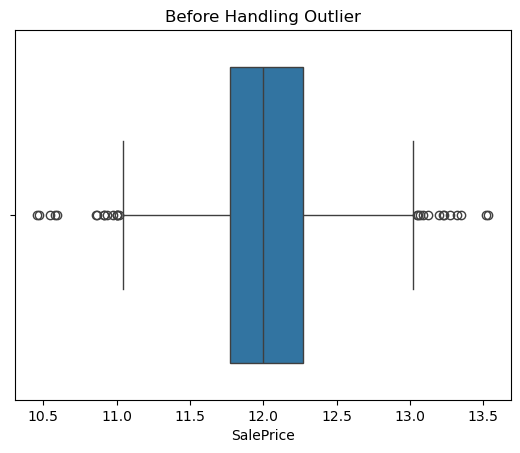

In [40]:
sns.boxplot(x=data['SalePrice'])
plt.title("Before Handling Outlier")
plt.show()

In [41]:
outlier_percent = {}

for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((data[col] < lower) | (data[col] > upper)).sum()
    percent = (outliers / len(data)) * 100

    outlier_percent[col] = percent

outlier_percent

{'MSSubClass': np.float64(0.0),
 'LotFrontage': np.float64(8.424657534246576),
 'LotArea': np.float64(9.04109589041096),
 'OverallQual': np.float64(0.136986301369863),
 'OverallCond': np.float64(8.561643835616438),
 'YearBuilt': np.float64(0.4794520547945206),
 'YearRemodAdd': np.float64(0.0),
 'MasVnrArea': np.float64(0.0),
 'BsmtFinSF1': np.float64(0.0),
 'BsmtFinSF2': np.float64(11.438356164383562),
 'BsmtUnfSF': np.float64(1.9863013698630139),
 'TotalBsmtSF': np.float64(3.5616438356164384),
 '1stFlrSF': np.float64(0.4794520547945206),
 '2ndFlrSF': np.float64(0.136986301369863),
 'LowQualFinSF': np.float64(1.7808219178082192),
 'GrLivArea': np.float64(0.684931506849315),
 'BsmtFullBath': np.float64(0.0684931506849315),
 'BsmtHalfBath': np.float64(5.616438356164384),
 'FullBath': np.float64(0.0),
 'HalfBath': np.float64(0.0),
 'BedroomAbvGr': np.float64(2.3972602739726026),
 'KitchenAbvGr': np.float64(4.657534246575342),
 'TotRmsAbvGrd': np.float64(2.054794520547945),
 'Fireplaces': 

In [42]:
for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    data[col] = data[col].clip(lower, upper)

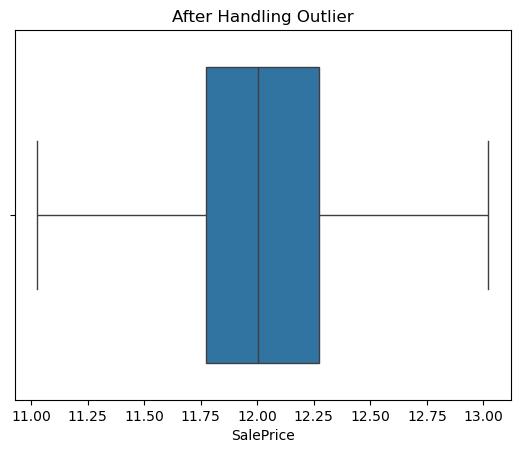

In [43]:
sns.boxplot(x=data['SalePrice'])
plt.title("After Handling Outlier")
plt.show()

In [44]:
outlier_percent = {}

for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((data[col] < lower) | (data[col] > upper)).sum()
    percent = (outliers / len(data)) * 100

    outlier_percent[col] = percent

outlier_percent

{'MSSubClass': np.float64(0.0),
 'LotFrontage': np.float64(0.0),
 'LotArea': np.float64(0.0),
 'OverallQual': np.float64(0.0),
 'OverallCond': np.float64(0.0),
 'YearBuilt': np.float64(0.0),
 'YearRemodAdd': np.float64(0.0),
 'MasVnrArea': np.float64(0.0),
 'BsmtFinSF1': np.float64(0.0),
 'BsmtFinSF2': np.float64(0.0),
 'BsmtUnfSF': np.float64(0.0),
 'TotalBsmtSF': np.float64(0.0),
 '1stFlrSF': np.float64(0.0),
 '2ndFlrSF': np.float64(0.0),
 'LowQualFinSF': np.float64(0.0),
 'GrLivArea': np.float64(0.0),
 'BsmtFullBath': np.float64(0.0),
 'BsmtHalfBath': np.float64(0.0),
 'FullBath': np.float64(0.0),
 'HalfBath': np.float64(0.0),
 'BedroomAbvGr': np.float64(0.0),
 'KitchenAbvGr': np.float64(0.0),
 'TotRmsAbvGrd': np.float64(0.0),
 'Fireplaces': np.float64(0.0),
 'GarageYrBlt': np.float64(0.0),
 'GarageCars': np.float64(0.0),
 'GarageArea': np.float64(0.0),
 'WoodDeckSF': np.float64(0.0),
 'OpenPorchSF': np.float64(0.0),
 'EnclosedPorch': np.float64(0.0),
 '3SsnPorch': np.float64(0.0),


#### Insights:
Outliers in numerical features were handled using the IQR method by capping extreme values within calculated lower and upper bounds. This approach reduces the impact of unusually high or low values without removing data points, thereby preserving the overall structure and distribution of the dataset. As a result, the data becomes more stable and suitable for modeling.

### 3. Feature scaling:

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data[num_cols] = scaler.fit_transform(data[num_cols])

In [46]:
data[num_cols].describe().T[['mean', 'std']]

,mean,std
MSSubClass,-4.659895e-16,1.000343
LotFrontage,-5.864411e-16,1.000343
LotArea,-1.367551e-15,1.000343
OverallQual,-2.287364e-16,1.000343
OverallCond,-4.355724e-16,1.000343
YearBuilt,1.178966e-15,1.000343
YearRemodAdd,4.496860e-15,1.000343
MasVnrArea,4.623395e-17,1.000343
BsmtFinSF1,1.703356e-17,1.000343
BsmtFinSF2,0.000000e+00,0.000000


#### Insights:
Numerical features were standardized using StandardScaler, which transforms the data to have a mean of zero and a standard deviation of one. This ensures that all features are on a similar scale, preventing variables with larger values from dominating the model and improving overall model performance.

# Data Preprocessing For Categorical Features:

### 1. Handling missing values:

In [47]:
data.dtypes.value_counts()

object     39
float64    37
Name: count, dtype: int64

In [48]:
for col in cat_cols[:3]:
    print(f"\n{col}")
    print(data[col].value_counts().head())


MSZoning
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

Street
Street
Pave    1454
Grvl       6
Name: count, dtype: int64

LotShape
LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64


In [49]:
for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

#### Insights:
The dataset contained categorical features in the form of text (object data type), which are not suitable for machine learning models. Missing values were handled using mode imputation.

### 2. Handling rare categories:

In [50]:
for col in cat_cols:
    if data[col].nunique() > 10:
        freq = data[col].value_counts(normalize=True)
        rare = freq[freq < 0.01].index
        data[col] = data[col].replace(rare, 'Other')

#### Insights:
Rare category handling was applied selectively to categorical features with a large number of unique values. Categories with very low frequency were grouped into a single category (“Other”) to reduce noise and improve model performance, while important and low-cardinality features were left unchanged.

### 3. Encoding:

In [51]:
data = pd.get_dummies(data, columns=cat_cols, drop_first=True)

In [52]:
data.dtypes.value_counts()

bool       188
float64     37
Name: count, dtype: int64

In [53]:
data.shape

(1460, 225)

In [54]:
data.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,0.424462,-0.164989,-0.208572,0.652644,-0.564161,1.053246,0.878668,1.203619,0.779431,0.0,...,False,False,False,False,True,False,False,False,True,False
1,-1.125202,0.664281,0.114384,-0.073068,2.030907,0.156179,-0.429577,-0.806841,0.888257,0.0,...,False,False,False,False,True,False,False,False,True,False
2,0.424462,0.015009,0.515830,0.652644,-0.564161,0.986797,0.830215,1.131524,0.654803,0.0,...,False,False,False,False,True,False,False,False,True,False
3,0.645073,-0.483994,0.101167,0.652644,-0.564161,-1.870528,-0.720298,-0.806841,0.384539,0.0,...,False,False,False,False,True,False,False,False,False,False
4,0.424462,0.859464,1.115941,1.378355,-0.564161,0.953572,0.733308,1.423411,0.754400,0.0,...,False,False,False,False,True,False,False,False,True,False


#### Insights:
Categorical features were converted into numerical form using one-hot encoding. As a result, all features are now numerical, and the number of columns has increased. This transformation ensures that the dataset is ready for model building.

## Data Preprocessing – Key Insights:
* Numerical features were preprocessed by handling missing values using median imputation, treating outliers through capping. Feature scaling was also performed to normalize the data.

* Categorical features were handled by imputing missing values using the mode and addressing rare categories. These features were then encoded using one-hot encoding to convert them into numerical format suitable for machine learning models.

* After preprocessing, all features were combined into a single dataset for model building.


# Feature Engineering:

### 1. Total area feature:

In [55]:
data['TotalSF'] = data['TotalBsmtSF'] + data['1stFlrSF'] + data['2ndFlrSF']

### 2. Total bathrooms:

In [56]:
data['TotalBath'] = data['FullBath'] + (0.5 * data['HalfBath'])

### 3. Age of house:

In [57]:
data['HouseAge'] = data['YrSold'] - data['YearBuilt']

### 4. Remodel age:

In [58]:
data['RemodelAge'] = data['YrSold'] - data['YearRemodAdd']

#### Insights:
Features such as total area, total bathrooms, house age and remodel age were derived to better represent the underlying characteristics of the data. These engineered features help improve model performance and provide deeper insights.

### Checking correlation with SalePrice:

In [59]:
corr = data.corr(numeric_only=True)['SalePrice'].sort_values()
print(corr)

ExterQual_TA       -0.607382
GarageFinish_Unf   -0.582450
KitchenQual_TA     -0.547957
BsmtQual_TA        -0.545156
HouseAge           -0.444123
                      ...   
EnclosedPorch            NaN
3SsnPorch                NaN
ScreenPorch              NaN
PoolArea                 NaN
MiscVal                  NaN
Name: SalePrice, Length: 229, dtype: float64


### Droping only weak features:

In [60]:
low_corr = corr[abs(corr) < 0.05].index
data = data.drop(columns=low_corr)

In [61]:
set(low_corr).intersection(set(data.columns))

set()

#### Insights:
The correlation of all numerical features with the target variable (Sale Price) was computed to identify their relevance. Features showing very low correlation (less than 0.05) were considered to have minimal influence on the target and were removed from the dataset. This helps in reducing noise and simplifying the model without significantly affecting performance.

### Checking multicollinearity:

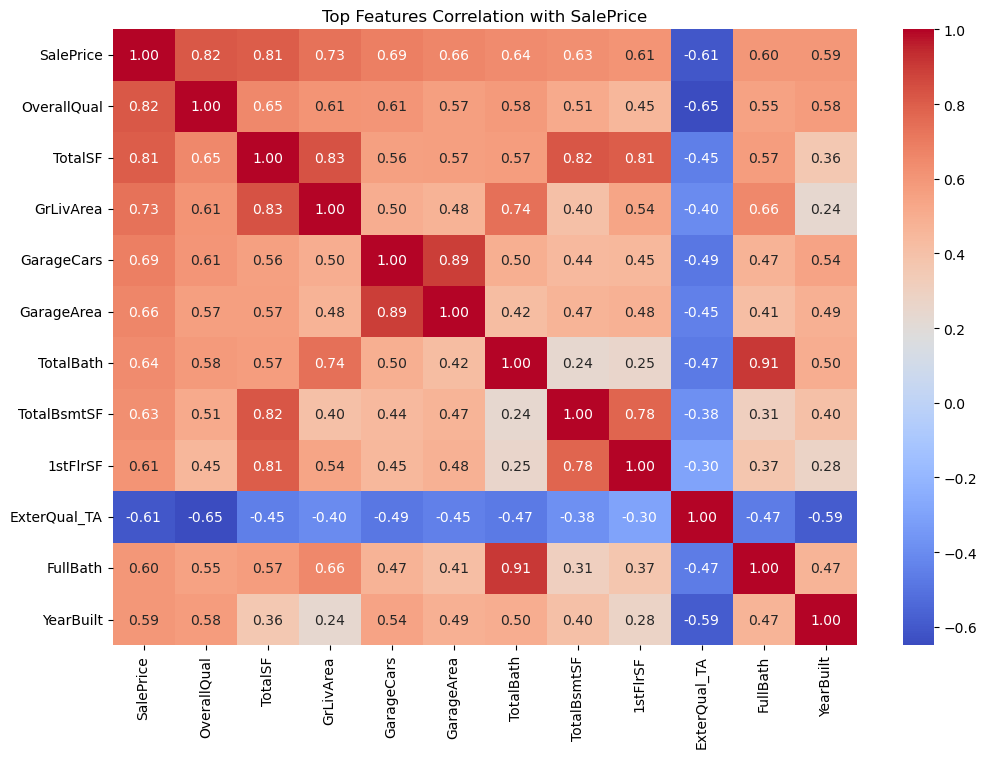

In [62]:
corr = data.corr(numeric_only=True)

top_features = corr['SalePrice'].abs().sort_values(ascending=False).head(12).index

plt.figure(figsize=(12, 8))
sns.heatmap(data[top_features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Top Features Correlation with SalePrice")
plt.show()

In [63]:
corr = data.corr(numeric_only=True)

for col in corr.columns:
    for row in corr.index:
        if col != row and abs(corr.loc[row, col]) > 0.8:
            print(col, row, corr.loc[row, col])

OverallQual SalePrice 0.818617082102861
BsmtFinSF1 BsmtFinType1_Unf -0.969786551555335
TotalBsmtSF TotalSF 0.8211225857413084
1stFlrSF TotalSF 0.8066656637703917
2ndFlrSF HouseStyle_2Story 0.8098126279760066
GrLivArea TotRmsAbvGrd 0.8299717872195033
GrLivArea TotalSF 0.8325682942942686
FullBath TotalBath 0.907209090065156
TotRmsAbvGrd GrLivArea 0.8299717872195033
GarageCars GarageArea 0.89455968020865
GarageArea GarageCars 0.89455968020865
SalePrice OverallQual 0.818617082102861
SalePrice TotalSF 0.8062222567469721
MSZoning_FV Neighborhood_Somerst 0.8628071099772279
MSZoning_RL MSZoning_RM -0.8085853546363103
MSZoning_RM MSZoning_RL -0.8085853546363103
Neighborhood_Somerst MSZoning_FV 0.8628071099772279
HouseStyle_2Story 2ndFlrSF 0.8098126279760066
RoofStyle_Gable RoofStyle_Hip -0.9334615823692307
RoofStyle_Hip RoofStyle_Gable -0.9334615823692307
Exterior1st_CemntBd Exterior2nd_CmentBd 0.9741710841939724
Exterior1st_HdBoard Exterior2nd_HdBoard 0.883271397030471
Exterior1st_MetalSd Exte

### Handling multicollinearity:

In [64]:
corr = data.corr(numeric_only=True)

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

to_drop = [col for col in upper.columns 
           if any(abs(upper[col]) > 0.8) and col != 'SalePrice']

print("Columns to drop:", to_drop)

Columns to drop: ['TotRmsAbvGrd', 'GarageArea', 'MSZoning_RM', 'Neighborhood_Somerst', 'HouseStyle_2Story', 'RoofStyle_Hip', 'Exterior2nd_CmentBd', 'Exterior2nd_HdBoard', 'Exterior2nd_MetalSd', 'Exterior2nd_VinylSd', 'Exterior2nd_Wd Sdng', 'MasVnrType_Stone', 'ExterQual_TA', 'BsmtQual_TA', 'BsmtFinType1_Unf', 'KitchenQual_TA', 'FireplaceQu_TA', 'GarageType_Detchd', 'GarageQual_TA', 'GarageCond_TA', 'SaleCondition_Partial', 'TotalSF', 'TotalBath']


In [65]:
data = data.drop(columns=['TotRmsAbvGrd', 'GarageArea'])

In [66]:
{'TotRmsAbvGrd', 'GarageArea'}.intersection(set(data.columns))

set()

#### Insights:
Multicollinearity was addressed by identifying highly correlated features. Instead of removing all correlated variables, only clearly redundant features such as TotRmsAbvGrd and GarageArea were removed. Important engineered features and categorical variables were retained to preserve meaningful information and improve model performance.

# Splitting Data For Training And Testing:

In [67]:
X = data.drop('SalePrice', axis=1)
y = data['SalePrice']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=30)

In [68]:
X_train.shape

(1168, 162)

In [69]:
X_test.shape

(292, 162)

# Model Building And Evaluation:

### 1. Linear Regression Model:

In [70]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

### Prediction:

In [71]:
y_pred = lr.predict(X_test)
y_pred

array([-0.04376991, -0.12399818, -0.16005859,  0.83731311, -0.97806758,
       -0.68598066, -0.79155691,  0.64433326,  1.39810112,  0.44932437,
       -1.44641848, -0.3333109 , -0.76150076, -0.87177743, -0.62363099,
        0.2440554 , -1.12421343, -0.01110244, -1.79404268,  0.52562172,
       -0.17694562, -0.55301742,  1.13855065,  1.72643769,  1.24459861,
        0.50839868, -1.02688303,  0.01466817, -0.56303846,  0.32889696,
       -0.34000819, -1.24680468,  0.56790998,  0.08425394, -0.93833289,
        0.31819089, -0.62581945, -0.22223879, -0.22361966,  0.99474791,
       -0.74770528,  0.48984748,  1.09031386, -0.77252463, -0.51483725,
        1.46992156,  2.53889022,  0.4173305 , -0.30093529, -0.62931426,
       -0.406108  , -0.62597801, -0.51477743, -0.61378615, -0.8686203 ,
        1.48811626, -1.69465234,  0.53098923, -0.61462703,  0.06627528,
       -0.45202877,  0.99172853, -0.39920554, -1.13754508, -0.18001083,
        0.68666298, -1.39543028, -0.73066317,  0.72298113, -0.32

### Evaluation:

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MSE:", mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MSE: 0.08770317348875406
MAE: 0.22542600631149953
RMSE: 0.29614721590579585
R2 Score: 0.9124912160270771


#### Insights:
The Linear Regression model demonstrated strong performance in predicting house prices. The R² score of 0.91 indicates that the model explains approximately 91% of the variance in the target variable, suggesting a good fit. The relatively low values of MAE and RMSE indicate that the prediction errors are small and the model is making accurate predictions. 

Overall, the results show that Linear Regression is effective in capturing the underlying relationships in the dataset, although some minor errors remain due to possible non-linear patterns.

### 2. Random Forest Regressor Model:

In [73]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor()
rf.fit(X_train, y_train)

RandomForestRegressor()

### Prediction:

In [74]:
y_pred_rf = rf.predict(X_test)

In [75]:
y_pred_rf

array([-2.94056630e-01, -2.46821970e-01, -5.24212294e-01,  7.48894581e-01,
       -7.71752455e-01, -5.71486446e-01, -5.16260347e-01,  3.80817097e-01,
        1.59774239e+00,  3.77786144e-01, -1.13378912e+00, -3.02046405e-01,
       -6.48853162e-01, -7.91804946e-01, -5.29036461e-01,  2.56718318e-01,
       -1.03542009e+00, -1.86357919e-01, -1.98809382e+00,  4.95380321e-01,
       -8.08637941e-02, -3.33479891e-01,  7.35116274e-01,  1.59022237e+00,
        1.50523464e+00,  4.77181390e-01, -6.99495149e-01,  7.75522425e-03,
       -4.44663127e-01,  3.82837455e-01,  1.89015625e-02, -1.40828327e+00,
        2.57797093e-01,  3.19304552e-01, -9.24326081e-01,  2.63280996e-01,
       -1.43843084e-01, -2.26793529e-01, -1.45486256e-01,  1.01435770e+00,
       -8.31191118e-01,  7.20952163e-01,  1.18396683e+00, -7.16139111e-01,
       -4.26921813e-01,  1.50691102e+00,  1.78482328e+00,  6.28704589e-01,
       -2.81802663e-01, -8.55696820e-01, -2.50394958e-01, -6.05287416e-01,
       -4.42494735e-01, -

### Evaluation:

In [76]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MSE:", mean_squared_error(y_test, y_pred_rf))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R2 Score:", r2_score(y_test, y_pred_rf))

MSE: 0.11916997932894118
MAE: 0.2461322541638336
RMSE: 0.3452100510253738
R2 Score: 0.8810941547230191


#### Insights:
The Random Forest model demonstrated good performance in predicting house prices, with an R² score of 0.88, indicating that it explains a significant portion of the variance in the target variable. The MAE and RMSE values suggest that the model produces reasonably accurate predictions with moderate error levels. 

However, when compared to the Linear Regression model, Random Forest shows slightly lower performance, as Linear Regression achieved a higher R² score and lower error metrics.

### 3. Hyperparameter Tuning of Random Forest:

In [77]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}
rf = RandomForestRegressor(random_state=30)

grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)
print("Best Parameters:", grid.best_params_)
best_rf = grid.best_estimator_

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Parameters: {'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


### Prediction:

In [78]:
y_pred_rf = best_rf.predict(X_test)

In [79]:
y_pred_rf

array([-3.73640137e-01, -2.36512277e-01, -4.58216412e-01,  8.14212296e-01,
       -7.22669241e-01, -5.01697197e-01, -6.30241588e-01,  4.20304469e-01,
        1.50790227e+00,  3.31579063e-01, -1.17788376e+00, -2.80705302e-01,
       -6.06817026e-01, -7.57683175e-01, -4.90769629e-01,  3.83917335e-01,
       -1.07847619e+00, -2.58843293e-01, -1.74405110e+00,  3.00005262e-01,
       -1.09067204e-01, -3.59233391e-01,  9.00120578e-01,  1.60923050e+00,
        1.21823730e+00,  6.04365639e-01, -7.20962019e-01, -2.62693578e-02,
       -4.70828651e-01,  4.52700108e-01, -8.04368777e-03, -8.72491647e-01,
        3.39629307e-01,  1.33176099e-01, -8.88958999e-01,  3.05622146e-01,
       -2.25190504e-01, -2.26005180e-01, -1.58227348e-01,  1.10439964e+00,
       -9.72013530e-01,  6.49184075e-01,  1.07305418e+00, -7.73534405e-01,
       -4.09141221e-01,  1.47603462e+00,  1.89557153e+00,  6.48227834e-01,
       -1.30533721e-01, -8.05331160e-01, -3.58843408e-01, -5.19316915e-01,
       -4.20385285e-01, -

### Evaluation:

In [80]:
print("MSE:", mean_squared_error(y_test, y_pred_rf))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R2 Score:", r2_score(y_test, y_pred_rf))

MSE: 0.12684476759569674
MAE: 0.2596181201831862
RMSE: 0.35615273071492337
R2 Score: 0.873436377224699


#### Insights:
After applying hyperparameter tuning to the Random Forest model, the performance did not improve compared to the default Random Forest. The tuned model resulted in slightly higher error values and a lower R² score, indicating a marginal decline in predictive accuracy. While hyperparameter tuning is generally used to optimize model performance, in this case, it suggests that the default configuration was already reasonably well-suited for the dataset.

# Model Comparison and Final Selection:

A comparison of all three models—Linear Regression, Random Forest, and Tuned Random Forest—reveals that Linear Regression performed the best for this dataset. It achieved the highest R² score (0.91) along with the lowest error metrics, indicating more accurate and reliable predictions.

The default Random Forest model showed slightly lower performance, suggesting that the dataset may not require complex non-linear modeling. After applying hyperparameter tuning, the Random Forest model did not show improvement and instead resulted in slightly higher errors and a lower R² score.

These results indicate that the underlying relationship in the data is largely linear, making Linear Regression the most suitable model for this problem. Therefore, Linear Regression is selected as the final model due to its simplicity, efficiency, and superior predictive performance.

# Conclusion:

In this project, exploratory data analysis and preprocessing techniques were applied to prepare the dataset for modeling. Feature engineering and selection helped improve the quality of the data by reducing redundancy and enhancing meaningful variables.

Multiple machine learning models, including Linear Regression and Random Forest, were implemented and evaluated. Among them, Linear Regression performed the best, achieving higher accuracy and lower error metrics compared to other models.

Overall, the project demonstrates that simpler models can sometimes outperform more complex models when the underlying relationships in the data are linear. The final model can be used for predicting house prices effectively.

# Recommendations for Customers:

Based on the analysis, customers should prioritize houses with larger living areas and better overall quality, as these features significantly impact price and value. It is also advisable to consider properties located in well-developed neighborhoods, as location plays a key role in long-term appreciation. Buyers should compare prices across similar features to ensure they are getting a fair deal. Additionally, focusing on houses with good basement and garage facilities can add extra utility and resale value. Finally, customers should balance their budget with essential features to make a practical and informed purchasing decision.

# Challenges and Solutions:

During the project, several challenges were encountered, including missing values in both numerical and categorical features, which were handled using median imputation and appropriate replacements. The presence of outliers in numerical data affected model performance and was addressed using the IQR method for capping extreme values. High skewness in some features required transformation to normalize the data distribution. Multicollinearity among features was another challenge, which was resolved by removing highly correlated variables to improve model stability. Additionally, categorical variables needed to be converted into numerical form using encoding techniques. These steps ensured better data quality and improved overall model performance.